# EDA v1 — Online Retail II: chất lượng dữ liệu và hành vi khách hàng

**Ngô Nguyên — MSSV 3124411191 — Nhóm 15.** Bài toán là phân cụm khách hàng dựa trên lịch sử.

Notebook trình bày câu hỏi, phép tính, bảng/hình và nhận xét theo từng phần. Báo cáo chi tiết
đã chốt tại [bao_cao_qua_trinh_eda.md](../../reports/bao_cao_qua_trinh_eda.md); notebook này
không chứa mã dựng lại toàn bộ văn bản báo cáo.

**Các phát hiện chính trên phiên bản nguồn đã kiểm tra:** 1.067.371 dòng, 53.628 chứng từ,
5.942 khách có mã; 22,77% dòng thiếu mã khách. Pipeline hiện có giữ 770.606 dòng mua của
5.839 khách. Các quy tắc mua/hủy/phí/trùng vẫn **Cần nhóm xác nhận**.

Nguồn: [Online Retail II — UCI](https://archive.ics.uci.edu/dataset/502/online+retail+ii),
`data/raw/online_retail_II.xlsx`, cả hai sheet, 01/12/2009–09/12/2011. Một dòng là mặt hàng
hoặc bút toán trên chứng từ; hóa đơn và khách hàng là hai cấp tổng hợp khác nhau.
Giá tính bằng GBP, thời gian nguồn chưa có múi giờ.

**Cách đọc:** chất lượng dữ liệu → đối chiếu pipeline → thời gian/quốc gia → hành vi →
khảo sát ngoại lệ và RFM. Code nằm trong notebook; chọn **Restart Kernel → Run All**.
Notebook v2 tự chạy độc lập nếu muốn đọc riêng phần ngoại lệ/RFM.

## 0. Thiết lập

Cửa sổ khảo sát là `[01/12/2009, 10/12/2011)`. Phân tích thô giữ C, dòng âm, trùng và
thiếu khách; hành vi mua dùng tập sau pipeline hiện có. Các hàm `src/` của nhóm được gọi
trong bộ nhớ, không sửa mã nguồn hay ghi vào raw/processed.

Các con số nhận xét dưới đây thuộc workbook có checksum hiển thị trong notebook. Nếu thay nguồn
hoặc chính sách, cần đọc lại bảng kết quả và cập nhật cả nhận xét lẫn báo cáo.

In [1]:
from __future__ import annotations
from pathlib import Path
import hashlib
import importlib.metadata
import platform
import re
import sys

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown, Image
from PIL import Image as PILImage

# Run All works from this directory, project/, or the repository root.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "data/raw/online_retail_II.xlsx").is_file()
               or (p / "project/data/raw/online_retail_II.xlsx").is_file())
if (PROJECT / "project/data/raw/online_retail_II.xlsx").is_file():
    PROJECT = PROJECT / "project"
PROJECT = PROJECT.resolve()
sys.path.insert(0, str(PROJECT))
from src.features import (build_customer_behavior_features, aggregate_purchase_orders,
                          audit_stock_codes, audit_c_documents)

ORIGINAL_COLUMNS = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
WINDOW_START = "2009-12-01"
REFERENCE_DATE = "2011-12-10"
EXPORT_TABLES = ("customer_behavior", "rfm", "rfm_transformed")
BLUE, ORANGE, GREY = "#245C88", "#C27623", "#65727C"
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

def checksum(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def identifier(values: pd.Series) -> pd.Series:
    return values.astype("string").str.strip().str.replace(r"(?<=\d)\.0$", "", regex=True).replace("", pd.NA)


def _counts(frame: pd.DataFrame, customer="CustomerID") -> dict:
    if customer not in frame:
        customer = "Customer ID"
    return {"rows": len(frame), "invoices": int(frame["Invoice"].nunique()), "customers": int(frame[customer].nunique())}

### Tái hiện chính sách tiền xử lý đã khảo sát

**Mốc chính sách của báo cáo:** các kết quả làm sạch, khảo sát khách hàng và RFM trong bản EDA này dùng chính sách tại commit `1c7ce32`. `main` đã có thay đổi tiền xử lý tại commit `d17492d`; các con số ở đây chưa đánh giá chính sách mới đó. Notebook giữ mã tái hiện chính sách cũ ngay trong một ô riêng để chạy độc lập, không sửa hoặc gọi API cũ đã bị xóa khỏi `src/preprocessing.py`. Các mô tả “hiện tại/current” trong kết quả đã lưu được hiểu tại mốc `1c7ce32`.

In [2]:
# Historical preprocessing policy replay, frozen at commit 1c7ce32.
# This cell audits the recorded EDA baseline; it is not the current team pipeline.
POLICY_COMMIT = "1c7ce32"
POLICY_SOURCE_SHA256 = "fe3cb23a1fe5ea84c69624053774ceb8bb9d48c48f6d512d5019970f4d7bcb8b"

SERVICE_CODES = {
    "POST", "DOT", "M", "C2", "C3", "D", "S", "B", "BANK CHARGES",
    "ADJUST", "ADJUST2", "AMAZONFEE", "CRUK", "TEST001", "TEST002",
}


def standardize(df: pd.DataFrame) -> pd.DataFrame:
    """Chuẩn hóa chuỗi: bỏ khoảng trắng, viết hoa mã hàng, đổi tên cột."""
    out = df.copy()
    out["Invoice"] = out["Invoice"].astype(str).str.strip().str.upper()
    out["StockCode"] = out["StockCode"].astype(str).str.strip().str.upper()
    out["Description"] = out["Description"].astype("string").str.strip()
    out["Country"] = out["Country"].astype("string").str.strip()
    return out.rename(columns={"Customer ID": "CustomerID"})


def reversed_sale_mask(sales: pd.DataFrame, cancels: pd.DataFrame) -> pd.Series:
    """Đánh dấu dòng bán đã bị hủy nguyên vẹn (cùng khách, mã hàng, số lượng, đơn giá).

    Khớp theo từng cặp một: mỗi dòng hủy chỉ "triệt tiêu" tối đa một dòng bán
    xảy ra trước nó.
    """
    key = ["CustomerID", "StockCode", "Price"]
    s = sales[key + ["Quantity", "InvoiceDate"]].copy()
    c = cancels[key + ["Quantity", "InvoiceDate"]].copy()
    c["Quantity"] = -c["Quantity"]
    s["rank"] = s.groupby(key + ["Quantity"]).cumcount()
    c["rank"] = c.groupby(key + ["Quantity"]).cumcount()
    merged = s.reset_index().merge(
        c, on=key + ["Quantity", "rank"], how="left", suffixes=("", "_cancel")
    )
    hit = merged["InvoiceDate_cancel"].notna() & (
        merged["InvoiceDate_cancel"] >= merged["InvoiceDate"]
    )
    return pd.Series(hit.to_numpy(), index=merged["index"]).reindex(sales.index).fillna(False)


def clean_transactions(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Áp dụng toàn bộ quy tắc tiền xử lý.

    Trả về `(sales, cancellations, log)`:
    - `sales`: dòng bán hợp lệ có mã khách hàng (đầu vào cho RFM);
    - `cancellations`: dòng hóa đơn hủy có mã khách hàng (dùng cho đặc trưng hoàn trả);
    - `log`: số dòng bị loại ở từng bước.
    """
    log: list[tuple[str, int]] = [("Dữ liệu gốc sau khi gộp sheet", len(raw))]
    df = standardize(raw)

    def step(name: str, frame: pd.DataFrame) -> pd.DataFrame:
        log.append((name, len(frame)))
        return frame

    cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate",
            "Price", "CustomerID", "Country"]
    df = step("Bỏ dòng trùng hoàn toàn", df.drop_duplicates(subset=cols))
    df = step("Bỏ dòng thiếu CustomerID", df.dropna(subset=["CustomerID"]))
    df = df.assign(CustomerID=df["CustomerID"].astype(int))
    df = step("Bỏ mã hàng dịch vụ/phí/thử nghiệm", df[~df["StockCode"].isin(SERVICE_CODES)])

    is_cancel = df["Invoice"].str.startswith("C")
    cancels = df[is_cancel & (df["Quantity"] < 0)]
    sales = df[~is_cancel]
    log.append(("Tách hóa đơn hủy (tiền tố C) sang bảng riêng", len(sales)))
    sales = step("Bỏ dòng bán có Quantity <= 0 hoặc Price <= 0", sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)])
    cancels = cancels[cancels["Price"] > 0]

    sales = sales.assign(LineValue=(sales["Quantity"] * sales["Price"]).round(2))
    cancels = cancels.assign(LineValue=(cancels["Quantity"] * cancels["Price"]).round(2))
    mask = reversed_sale_mask(sales, cancels)
    sales = step("Bỏ dòng bán đã bị hủy nguyên vẹn (đơn lỗi/ngoại lai)", sales[~mask])

    sales = sales.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
    cancels = cancels.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
    return sales, cancels, pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])

In [3]:
def descriptive(frame: pd.DataFrame, columns: list[str], population: str) -> pd.DataFrame:
    records = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce")
        finite = values[np.isfinite(values)]
        q1, median, q3, p95, p99 = finite.quantile([.25, .5, .75, .95, .99])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        below, above = int(finite.lt(lower).sum()), int(finite.gt(upper).sum())
        records.append(dict(population=population, variable=column, count=int(finite.count()), missing=int(values.isna().sum()),
                            mean=finite.mean(), median=median, minimum=finite.min(), maximum=finite.max(),
                            q1=q1, q3=q3, iqr=iqr, p95=p95, p99=p99, std=finite.std(), skewness=finite.skew(),
                            iqr_lower=lower, iqr_upper=upper, below_iqr=below, above_iqr=above,
                            outside_iqr=below + above, outside_iqr_pct=100 * (below + above) / len(finite) if len(finite) else np.nan,
                            denominator=int(len(finite))))
    return pd.DataFrame(records)

def _canonical(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    for col in ["Invoice", "StockCode", "CustomerID"]:
        if col in out:
            out[col] = identifier(out[col])
    if "InvoiceDate" in out:
        out["InvoiceDate"] = pd.to_datetime(out["InvoiceDate"])
    return out

def _compare_frames(calculated, stored) -> tuple[bool, str]:
    try:
        pd.testing.assert_frame_equal(_canonical(calculated).reset_index(drop=True),
                                      _canonical(stored.loc[:, calculated.columns]).reset_index(drop=True),
                                      check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-9)
        return True, "All rows/columns in stored order equal after identifier/date normalization; numeric atol=1e-9, rtol=1e-12."
    except (AssertionError, KeyError) as exc:
        return False, str(exc)[:900]

def table(name, limit=15):
    frame = tables[name]
    display(Markdown(f"**{name}** — {len(frame):,} dòng kết quả."))
    if name in EXPORT_TABLES:
        display(Markdown(f"[CSV bàn giao]({OUTPUT_LINK}/tables/{name}.csv)"))
    else:
        display(Markdown(f"Bảng giữ trong biến `tables[\"{name}\"]`; không xuất CSV trung gian."))
    if name.startswith("outlier_"):
        columns = ["population", "variable", "count", "median", "q1", "q3", "iqr", "p95", "p99", "maximum", "outside_iqr", "outside_iqr_pct"]
    elif name in {"descriptive_transactions", "feature_profile", "rfm_profile"}:
        columns = ["population", "variable", "count", "missing", "mean", "median", "minimum", "maximum", "std", "skewness"]
    elif name == "customer_behavior":
        columns = ["Customer ID", "n_orders", "total_purchase_value", "avg_order_value", "n_stock_codes_candidate", "avg_purchase_gap_days", "return_rate"]
    else:
        columns = list(frame.columns)
    display(frame.loc[:, [column for column in columns if column in frame]].head(limit))
    if len(frame) > limit:
        display(Markdown(f"Đang xem {limit:,}/{len(frame):,} dòng. Sau Run All, dùng `tables[\"{name}\"]` để xem đầy đủ."))

### Đọc dữ liệu gốc và ghi nhận phiên bản

Đọc cả hai sheet; không đọc bảng kết quả có sẵn của notebook khác.

In [4]:
project = PROJECT
NOTEBOOK_NAME = "eda_v1.ipynb"
code_paths = [PROJECT / "src/preprocessing.py", PROJECT / "src/features.py"]
code_before = {path.relative_to(PROJECT).as_posix(): checksum(path) for path in code_paths}
OUTPUT_LINK = "../../experiments/eda_rebuild"

source = project / "data/raw/online_retail_II.xlsx"
out = project / "experiments/eda_rebuild"
table_dir = out / "tables"
figure_dir = project / "notebooks/01_eda/figures"
table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
source_before = checksum(source)
print("Reading all workbook sheets (source read-only)...", flush=True)
sheets = pd.read_excel(source, sheet_name=None, engine="openpyxl")
if len(sheets) != 2 or any(list(part.columns) != ORIGINAL_COLUMNS for part in sheets.values()):
    raise ValueError("Expected two sheets with eight original columns; inspect changed input first.")
tables: dict[str, pd.DataFrame] = {}
summary = {}
figures = []
raw = pd.concat([part.assign(Sheet=name) for name, part in sheets.items()], ignore_index=True)
original = raw.loc[:, ORIGINAL_COLUMNS]

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.grid": False,
                     "savefig.facecolor": "white"})
def save(fig, name, title, population, table_names, notebook="eda_v1.ipynb"):
    fig.savefig(figure_dir / name, dpi=180, bbox_inches="tight")
    plt.close(fig)
    figures.append(dict(name=name, title=title, population=population, table_names=table_names, notebook=NOTEBOOK_NAME))
    display(Image(filename=str(figure_dir / name), width=1100))
def count_format(ax, axis="y"):
    def compact(x, _):
        if abs(x) >= 1_000_000:
            return f"{x/1_000_000:g}m"
        if abs(x) >= 1_000:
            return f"{x/1_000:g}k"
        return f"{x:,.0f}"
    formatter = FuncFormatter(compact)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)

Reading all workbook sheets (source read-only)...


<a id="eda-overview"></a>

## 1. Cấu trúc và phạm vi dữ liệu

Kiểm tra từng sheet, kiểu dữ liệu, dòng đầu/cuối và phần thời gian chồng lấn. Các mã là định danh, không diễn giải trung bình mã khách hàng.

In [5]:
tables["sheet_profile"] = pd.DataFrame([
    {"sheet": name, "rows": len(part), "columns": len(part.columns), "date_min": part.InvoiceDate.min(),
     "date_max": part.InvoiceDate.max(), "invoices": part.Invoice.nunique(), "customers": part["Customer ID"].nunique(),
     "duplicate_excess": int(part.duplicated(ORIGINAL_COLUMNS).sum())}
    for name, part in sheets.items()])
tables["schema"] = pd.DataFrame([{"sheet": name, "column": col, "dtype": str(part[col].dtype),
                                           "non_null": int(part[col].notna().sum()), "unique_non_null": part[col].nunique()}
                                          for name, part in sheets.items() for col in ORIGINAL_COLUMNS])
tables["samples"] = pd.concat([pd.concat([part.head(3).assign(position="head"), part.tail(3).assign(position="tail")]).assign(sheet=name)
                                 for name, part in sheets.items()], ignore_index=True)
start = max(part.InvoiceDate.min() for part in sheets.values())
end = min(part.InvoiceDate.max() for part in sheets.values())
tables["overlap"] = pd.DataFrame([{"overlap_start": start, "overlap_end": end, "calendar_dates_inclusive": (end.normalize() - start.normalize()).days + 1,
                                  "rows_in_overlap": int(raw.InvoiceDate.between(start, end).sum())}])

table("sheet_profile")
table("schema", 20)
table("samples", 12)
table("overlap")

**sheet_profile** — 2 dòng kết quả.

Bảng giữ trong biến `tables["sheet_profile"]`; không xuất CSV trung gian.

,sheet,rows,columns,date_min,date_max,invoices,customers,duplicate_excess
0,Year 2009-2010,525461,8,2009-12-01 07:45:00,2010-12-09 20:01:00,28816,4383,6865
1,Year 2010-2011,541910,8,2010-12-01 08:26:00,2011-12-09 12:50:00,25900,4372,5268


**schema** — 16 dòng kết quả.

Bảng giữ trong biến `tables["schema"]`; không xuất CSV trung gian.

,sheet,column,dtype,non_null,unique_non_null
0,Year 2009-2010,Invoice,object,525461,28816
1,Year 2009-2010,StockCode,object,525461,4632
2,Year 2009-2010,Description,object,522533,4681
3,Year 2009-2010,Quantity,int64,525461,825
4,Year 2009-2010,InvoiceDate,datetime64[us],525461,25296
5,Year 2009-2010,Price,float64,525461,1606
6,Year 2009-2010,Customer ID,float64,417534,4383
7,Year 2009-2010,Country,str,525461,40
8,Year 2010-2011,Invoice,object,541910,25900
9,Year 2010-2011,StockCode,object,541910,4070


... (2 outputs left out)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,position,sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.9500,"13,085.0000",United Kingdom,head,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,"13,085.0000",United Kingdom,head,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.7500,"13,085.0000",United Kingdom,head,Year 2009-2010
3,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.7500,"17,530.0000",United Kingdom,tail,Year 2009-2010
4,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.7500,"17,530.0000",United Kingdom,tail,Year 2009-2010
5,538171,21931,JUMBO STORAGE BAG SUKI,2,2010-12-09 20:01:00,1.9500,"17,530.0000",United Kingdom,tail,Year 2009-2010
6,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.5500,"17,850.0000",United Kingdom,head,Year 2010-2011
7,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.3900,"17,850.0000",United Kingdom,head,Year 2010-2011
8,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.7500,"17,850.0000",United Kingdom,head,Year 2010-2011
9,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.1500,"12,680.0000",France,tail,Year 2010-2011


**overlap** — 1 dòng kết quả.

Bảng giữ trong biến `tables["overlap"]`; không xuất CSV trung gian.

,overlap_start,overlap_end,calendar_dates_inclusive,rows_in_overlap
0,2010-12-01 08:26:00,2010-12-09 20:01:00,9,45046


**Kết quả:** sheet đầu có 525.461 dòng, sheet sau có 541.910 dòng. Thời gian chồng lấn
là 01–09/12/2010. Vì một hóa đơn có nhiều mặt hàng, số dòng không thay cho số hóa đơn;
tương tự, một khách có thể xuất hiện ở nhiều hóa đơn.

**Ý nghĩa:** gộp sheet là bước thu thập dữ liệu, chưa phải làm sạch. Phải so tám cột gốc
để xác định nội dung trùng; không xóa mọi dòng chỉ vì ngày nằm trong vùng chồng lấn.

### Từ điển tám cột nguồn

| Cột | Ý nghĩa và đơn vị |
|---|---|
| Invoice | Mã chứng từ; tiền tố C là hủy theo UCI; định danh |
| StockCode | Mã mặt hàng hoặc mã nghiệp vụ; cần kiểm kê trước khi gọi là sản phẩm |
| Description | Mô tả mặt hàng hoặc nghiệp vụ; văn bản có thể thiếu |
| Quantity | Lượng ghi trên dòng, có dấu; đơn vị hàng theo nguồn |
| InvoiceDate | Thời điểm chứng từ; nguồn không chỉ định múi giờ |
| Price | Đơn giá GBP trên một đơn vị |
| Customer ID | Mã khách hàng; có thể thiếu; định danh |
| Country | Nhãn quốc gia của khách theo nguồn |


<a id="eda-missing"></a>

## 2.1. Dữ liệu thiếu

Mẫu số là số dòng thô toàn workbook hoặc số dòng từng sheet ghi ở bảng. Thiếu Customer ID làm giao dịch không thể gán về một khách hàng đáng tin cậy.

**missing** — 8 dòng kết quả.

Bảng giữ trong biến `tables["missing"]`; không xuất CSV trung gian.

,column,missing_rows,denominator_rows,missing_pct
0,Invoice,0,1067371,0.0000
1,StockCode,0,1067371,0.0000
2,Description,4382,1067371,0.4105
3,Quantity,0,1067371,0.0000
4,InvoiceDate,0,1067371,0.0000
5,Price,0,1067371,0.0000
6,Customer ID,243007,1067371,22.7669
7,Country,0,1067371,0.0000


**missing_by_sheet** — 16 dòng kết quả.

Bảng giữ trong biến `tables["missing_by_sheet"]`; không xuất CSV trung gian.

,sheet,column,missing_rows,denominator_rows,missing_pct
0,Year 2009-2010,Invoice,0,525461,0.0000
1,Year 2009-2010,StockCode,0,525461,0.0000
2,Year 2009-2010,Description,2928,525461,0.5572
3,Year 2009-2010,Quantity,0,525461,0.0000
4,Year 2009-2010,InvoiceDate,0,525461,0.0000
5,Year 2009-2010,Price,0,525461,0.0000
6,Year 2009-2010,Customer ID,107927,525461,20.5395
7,Year 2009-2010,Country,0,525461,0.0000
8,Year 2010-2011,Invoice,0,541910,0.0000
9,Year 2010-2011,StockCode,0,541910,0.0000


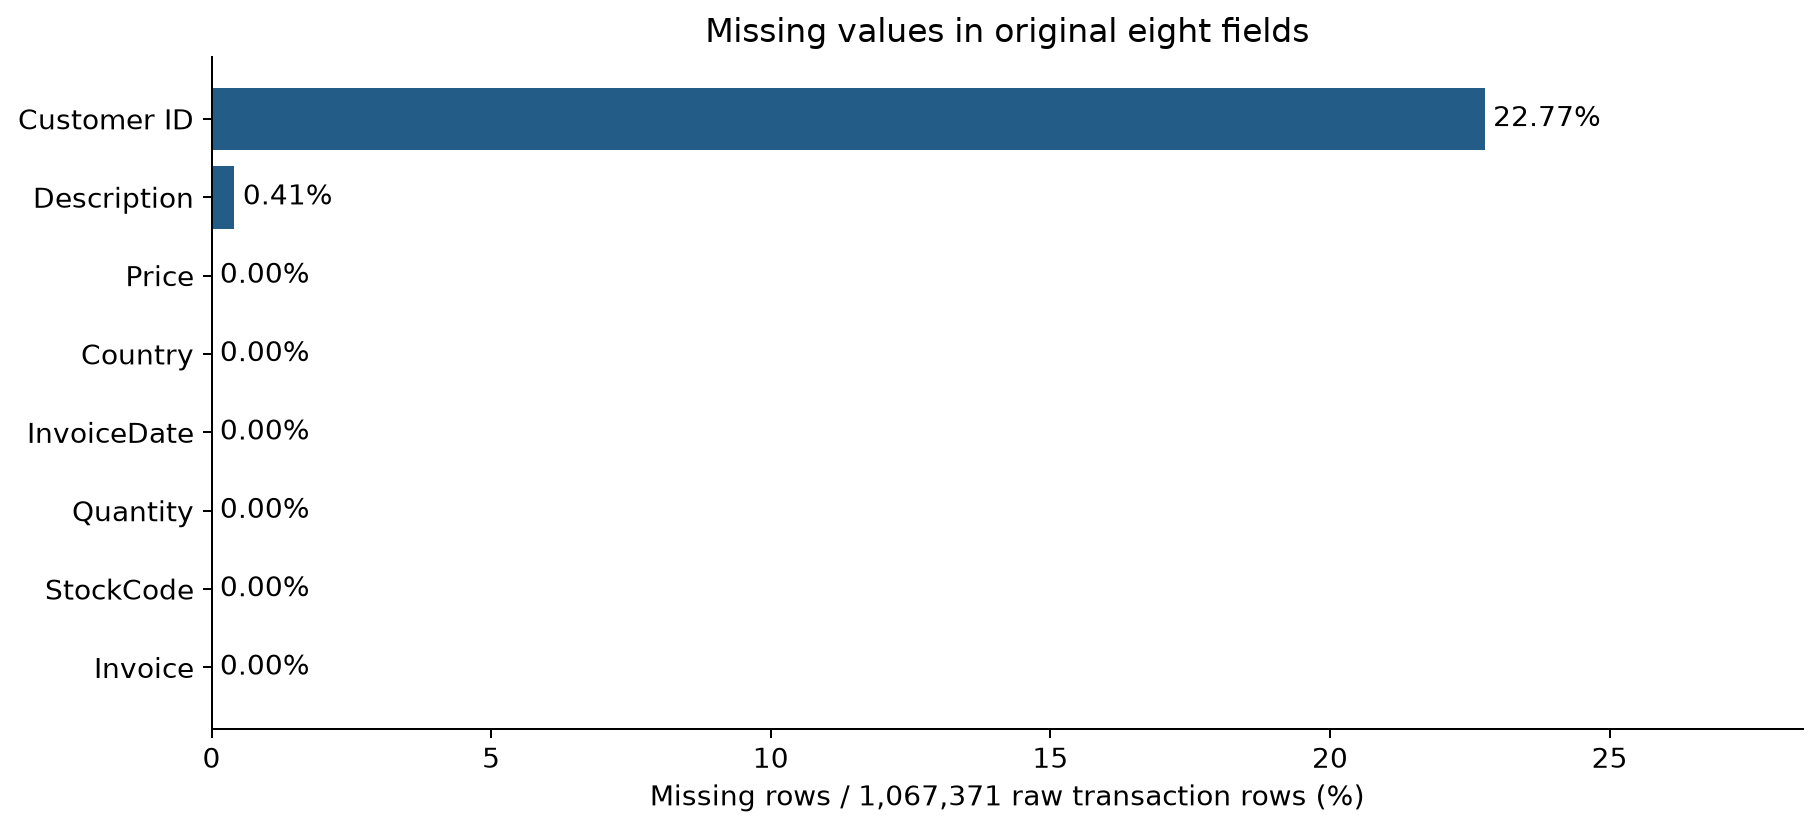

In [6]:
tables["missing"] = pd.DataFrame({"column": ORIGINAL_COLUMNS, "missing_rows": original.isna().sum().values,
                                    "denominator_rows": len(raw), "missing_pct": original.isna().mean().values * 100})
tables["missing_by_sheet"] = pd.concat([
    pd.DataFrame({"sheet": name, "column": ORIGINAL_COLUMNS, "missing_rows": part.isna().sum().values,
                  "denominator_rows": len(part), "missing_pct": part.isna().mean().values * 100}) for name, part in sheets.items()], ignore_index=True)

table("missing")
table("missing_by_sheet", 20)

fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
m = tables["missing"].sort_values("missing_pct")
ax.barh(m.column, m.missing_pct, color=BLUE)
for y, value in enumerate(m.missing_pct):
    ax.text(value + .15, y, f"{value:.2f}%", va="center")
ax.set(xlabel=f"Missing rows / {len(raw):,} raw transaction rows (%)", title="Missing values in original eight fields")
ax.set_xlim(0, max(m.missing_pct)*1.25)
save(fig, "missing_values_by_column.png", "Missing values by original field", "Raw rows, including C and anonymous transactions", ["missing"])

**Kết quả:** 243,007/1,067,371 dòng
(22.77%) thiếu Customer ID; 4.382 dòng thiếu Description.
Các cột nguồn còn lại không có giá trị thiếu trên phiên bản đã kiểm tra.

**Ý nghĩa:** không thể gán đáng tin cậy các dòng thiếu ID vào một khách để phân cụm.
Giữ chúng khi mô tả hoạt động cấp dòng; không tạo mã khách giả hoặc gom thành một người.
Description thiếu cần được xem cùng StockCode và chứng từ. **Cần nhóm xác nhận** phạm vi
khách có định danh dùng cho feature engineering.

<a id="eda-duplicates"></a>

## 2.2. Trùng và tác động

So sánh trùng dư tám cột, trong từng sheet, mẫu chung duy nhất giữa sheet và số bản sao ở sheet sau. Các định nghĩa được lưu riêng, không cộng chồng các nhóm.

In [7]:
a, b = list(sheets.values())
a_unique, b_unique = a.drop_duplicates(ORIGINAL_COLUMNS), b.drop_duplicates(ORIGINAL_COLUMNS)
shared = a_unique.merge(b_unique, on=ORIGINAL_COLUMNS, how="inner")
shared_second_rows = len(b.merge(a_unique, on=ORIGINAL_COLUMNS, how="inner"))
duplicate_excess = int(original.duplicated().sum())
within = sum(int(part.duplicated().sum()) for part in sheets.values())
tables["duplicates"] = pd.DataFrame([
    {"definition": "Global excess: duplicated(8 original columns, keep='first')", "count": duplicate_excess, "denominator": len(raw)},
    {"definition": "All rows belonging to a duplicate group: keep=False", "count": int(original.duplicated(keep=False).sum()), "denominator": len(raw)},
    {"definition": "Sum of excess duplicates separately inside each sheet", "count": within, "denominator": len(raw)},
    {"definition": "Distinct original 8-column patterns present in both sheets", "count": len(shared), "denominator": len(raw)},
    {"definition": "Rows in second sheet matching a pattern in first (incl repeated copies)", "count": shared_second_rows, "denominator": len(b)},
    {"definition": "Second-sheet extra copies of a shared pattern", "count": shared_second_rows - len(shared), "denominator": len(b)}])
assert duplicate_excess == within + len(shared)
raw["LineValue"] = raw.Quantity * raw.Price
raw["Invoice"] = identifier(raw.Invoice)
raw["StockCode"] = identifier(raw.StockCode)
raw["is_c"] = raw.Invoice.str.upper().str.startswith("C", na=False)
dedup = raw.loc[~original.duplicated()].copy()
tables["duplicate_impact"] = pd.DataFrame([
    dict(population=name, **_counts(frame), signed_line_value_gbp=frame.LineValue.sum(), positive_line_value_gbp=frame.loc[frame.LineValue.gt(0), "LineValue"].sum())
    for name, frame in [("raw_all_rows", raw), ("raw_original_8col_deduplicated", dedup)]])

table("duplicates", 20)
table("duplicate_impact")

**duplicates** — 6 dòng kết quả.

Bảng giữ trong biến `tables["duplicates"]`; không xuất CSV trung gian.

,definition,count,denominator
0,"Global excess: duplicated(8 original columns, keep='first')",34335,1067371
1,All rows belonging to a duplicate group: keep=False,67242,1067371
2,Sum of excess duplicates separately inside each sheet,12133,1067371
3,Distinct original 8-column patterns present in both sheets,22202,1067371
4,Rows in second sheet matching a pattern in first (incl repeated copies),22523,541910
5,Second-sheet extra copies of a shared pattern,321,541910


**duplicate_impact** — 2 dòng kết quả.

Bảng giữ trong biến `tables["duplicate_impact"]`; không xuất CSV trung gian.

,population,rows,invoices,customers,signed_line_value_gbp,positive_line_value_gbp
0,raw_all_rows,1067371,53628,5942,"19,287,250.5680","20,972,968.1380"
1,raw_original_8col_deduplicated,1033036,53628,5942,"18,855,533.6980","20,476,634.0180"


**Kết quả:** có 34.335 dòng trùng dư trên tám cột: 12.133 dòng dư khi kiểm tra riêng
từng sheet và 22.202 mẫu nội dung chung giữa hai sheet. Sheet sau có 22.523 dòng khớp mẫu
chung, nhiều hơn 321 vì một mẫu có thể được lặp thêm trong chính sheet đó.

**Ý nghĩa:** 22.202 và 22.523 là hai cách đếm khác nhau. Trùng dòng có thể làm tăng lượng
và giá trị mua dù số hóa đơn không đổi. Đếm giống hệt chưa đủ chứng minh lỗi nhập liệu;
chính sách loại trùng đang được tái hiện, **Cần nhóm xác nhận** trước khi dùng chính thức.

<a id="eda-special"></a>

## 2.3. Chứng từ C, giá trị đặc biệt và mã hàng

Đếm từng điều kiện riêng; các điều kiện có thể chồng lấn. Regex chỉ kiểm tra hình dạng StockCode, không xác nhận đó là sản phẩm.

**anomalies** — 7 dòng kết quả.

Bảng giữ trong biến `tables["anomalies"]`; không xuất CSV trung gian.

,category,rows,denominator_rows,pct,invoices,signed_line_value_gbp,interpretation,proposal
0,Invoice prefix C,19494,1067371,1.8264,8292,"-1,526,667.8600",Cancellation indicator; not automatically a verified matched return.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
1,Quantity < 0,22950,1067371,2.1501,11684,"-1,527,041.4300","May represent cancellations, adjustments or stock movements.",Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
2,Quantity = 0,0,1067371,0.0000,0,0.0000,Review; not a positive purchase.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
3,Price < 0,5,1067371,0.0005,5,"-158,676.1400",Review adjustment/accounting examples.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
4,Price = 0,6202,1067371,0.5811,5379,0.0000,Free items or adjustments possible; not assume error.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
5,Quantity < 0 without C,3457,1067371,0.3239,3393,0.0000,Inventory/adjustment candidates; inspect descriptions.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.
6,C with Quantity >= 0,1,1067371,0.0001,1,373.5700,Cancellation-sign exception; inspect separately.,Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.


**anomaly_examples** — 26 dòng kết quả.

Bảng giữ trong biến `tables["anomaly_examples"]`; không xuất CSV trung gian.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,LineValue,category
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.9500,"16,321.0000",Australia,Year 2009-2010,-35.4000,Invoice prefix C
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.6500,"16,321.0000",Australia,Year 2009-2010,-9.9000,Invoice prefix C
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.2500,"16,321.0000",Australia,Year 2009-2010,-17.0000,Invoice prefix C
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.1000,"16,321.0000",Australia,Year 2009-2010,-12.6000,Invoice prefix C
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.9500,"16,321.0000",Australia,Year 2009-2010,-35.4000,Invoice prefix C
5,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.9500,"16,321.0000",Australia,Year 2009-2010,-35.4000,Quantity < 0
6,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.6500,"16,321.0000",Australia,Year 2009-2010,-9.9000,Quantity < 0
7,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.2500,"16,321.0000",Australia,Year 2009-2010,-17.0000,Quantity < 0
8,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.1000,"16,321.0000",Australia,Year 2009-2010,-12.6000,Quantity < 0
9,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.9500,"16,321.0000",Australia,Year 2009-2010,-35.4000,Quantity < 0


... (5 outputs left out)

**stock_audit** — 5,304 dòng kết quả.

Bảng giữ trong biến `tables["stock_audit"]`; không xuất CSV trung gian.

,StockCode,n_rows,example_descriptions,matches_product_code_pattern,classification
0,10002,400,INFLATABLE POLITICAL GLOBE,True,product_pattern_candidate_UNVERIFIED
1,10002R,3,ROBOT PENCIL SHARPNER,True,product_pattern_candidate_UNVERIFIED
2,10080,31,GROOVY CACTUS INFLATABLE | check,True,product_pattern_candidate_UNVERIFIED
3,10109,2,BENDY COLOUR PENCILS,True,product_pattern_candidate_UNVERIFIED
4,10120,79,DOGGY RUBBER | Zebra invcing error,True,product_pattern_candidate_UNVERIFIED
5,10123C,71,HEARTS WRAPPING TAPE,True,product_pattern_candidate_UNVERIFIED
6,10123G,21,ARMY CAMO WRAPPING TAPE,True,product_pattern_candidate_UNVERIFIED
7,10124A,20,SPOTS ON RED BOOKCOVER TAPE,True,product_pattern_candidate_UNVERIFIED
8,10124C,1,,True,product_pattern_candidate_UNVERIFIED
9,10124G,11,ARMY CAMO BOOKCOVER TAPE,True,product_pattern_candidate_UNVERIFIED


Đang xem 10/5,304 dòng. Sau Run All, dùng `tables["stock_audit"]` để xem đầy đủ.

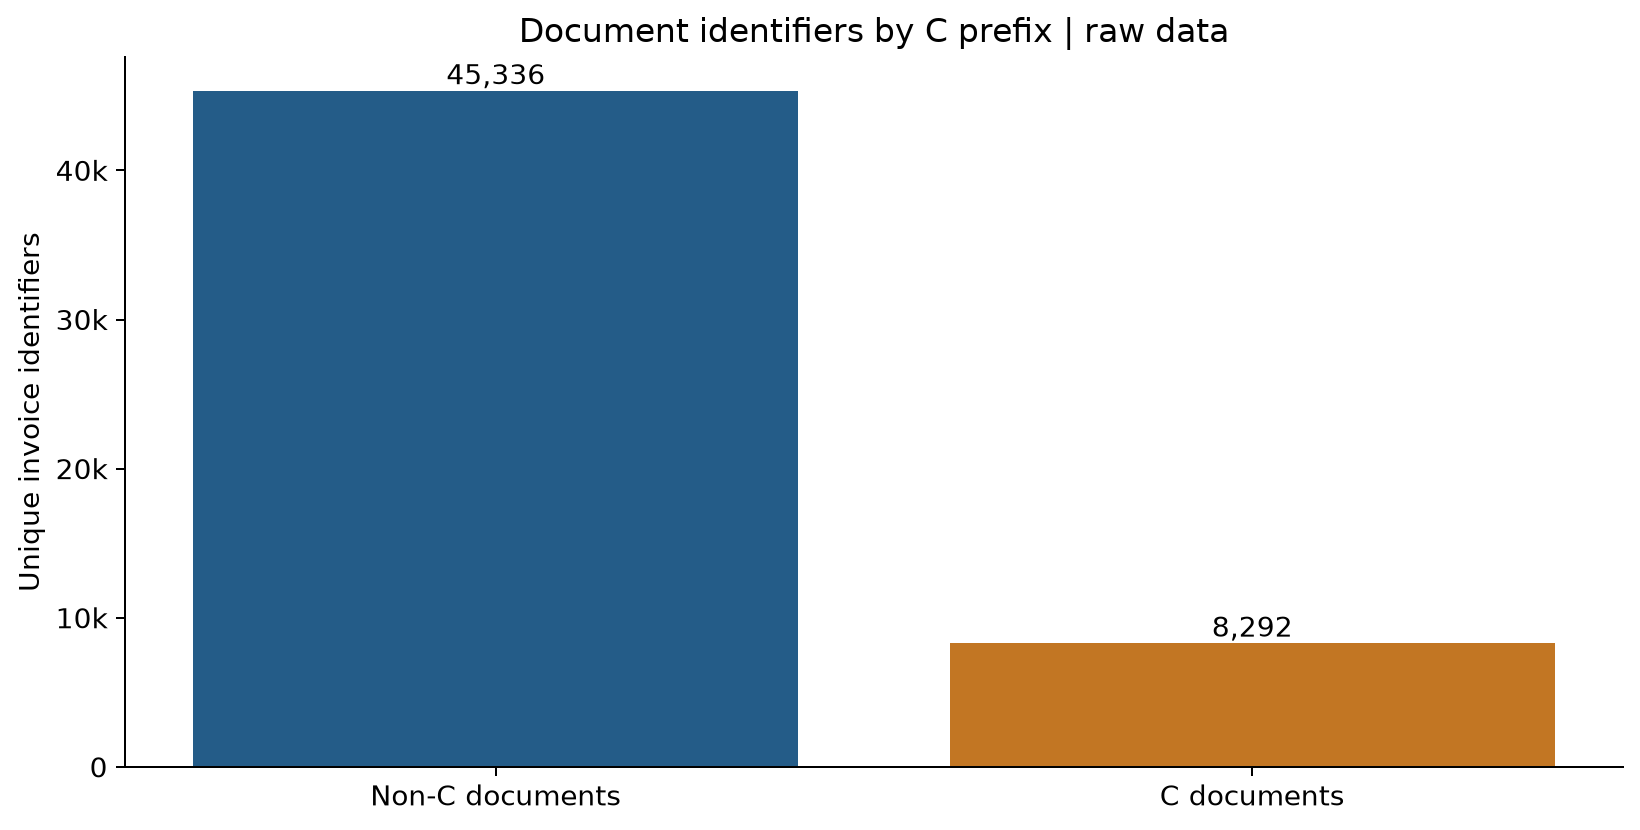

In [8]:
anomaly_masks = {
    "Invoice prefix C": raw.is_c, "Quantity < 0": raw.Quantity.lt(0), "Quantity = 0": raw.Quantity.eq(0),
    "Price < 0": raw.Price.lt(0), "Price = 0": raw.Price.eq(0),
    "Quantity < 0 without C": raw.Quantity.lt(0) & ~raw.is_c,
    "C with Quantity >= 0": raw.is_c & raw.Quantity.ge(0)}
notes = {"Invoice prefix C": "Cancellation indicator; not automatically a verified matched return.",
         "Quantity < 0": "May represent cancellations, adjustments or stock movements.",
         "Quantity = 0": "Review; not a positive purchase.", "Price < 0": "Review adjustment/accounting examples.",
         "Price = 0": "Free items or adjustments possible; not assume error.",
         "Quantity < 0 without C": "Inventory/adjustment candidates; inspect descriptions.",
         "C with Quantity >= 0": "Cancellation-sign exception; inspect separately."}
tables["anomalies"] = pd.DataFrame([dict(category=name, rows=int(mask.sum()), denominator_rows=len(raw),
                                           pct=100 * mask.mean(), invoices=raw.loc[mask, "Invoice"].nunique(),
                                           signed_line_value_gbp=raw.loc[mask, "LineValue"].sum(), interpretation=notes[name],
                                           proposal="Cần nhóm xác nhận: preserve audit; separate from selected positive purchases.")
                                         for name, mask in anomaly_masks.items()])
tables["anomaly_examples"] = pd.concat([raw.loc[mask, ORIGINAL_COLUMNS + ["Sheet", "LineValue"]].head(5).assign(category=name)
                                            for name, mask in anomaly_masks.items()], ignore_index=True)
stock = audit_stock_codes(raw, window_start=WINDOW_START, reference_date=REFERENCE_DATE)
stock["classification"] = np.where(stock.StockCode.isin(SERVICE_CODES), "pipeline_service_exclusion",
                                       np.where(stock.matches_product_code_pattern, "product_pattern_candidate_UNVERIFIED", "unknown"))
tables["stock_audit"] = stock
special = stock.loc[~stock.matches_product_code_pattern | stock.StockCode.isin(SERVICE_CODES)].copy()
special["suggested_review_role"] = special.StockCode.map({"POST": "postage", "DOT": "postage", "BANK CHARGES": "fee", "AMAZONFEE": "fee", "C2": "fee", "D": "discount_adjustment", "M": "manual_adjustment", "B": "accounting_adjustment", "S": "sample"}).fillna("unknown_requires_review")
tables["special_stock_codes"] = special.sort_values("n_rows", ascending=False)

table("anomalies", 20)
table("anomaly_examples", 12)
table("special_stock_codes", 20)
table("stock_audit", 10)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
doc = raw.groupby("is_c").Invoice.nunique().reindex([False, True])
ax.bar(["Non-C documents", "C documents"], doc, color=[BLUE, ORANGE])
for x, val in enumerate(doc): ax.text(x, val, f"{val:,}", ha="center", va="bottom")
ax.set(ylabel="Unique invoice identifiers", title="Document identifiers by C prefix | raw data")
count_format(ax)
save(fig, "invoices_by_c_prefix.png", "Invoice identifiers by C prefix", "Raw unique invoice identifiers", ["anomalies"])

**Kết quả:** 19.494 dòng có tiền tố C; 22.950 dòng có Quantity âm, trong đó 3.457 dòng
không có C. Có 6.202 dòng giá 0, 5 dòng giá âm, không có Quantity bằng 0 và một dòng C có
lượng không âm. Các điều kiện có giao nhau, không cộng các tỷ lệ như các nhóm loại trừ nhau.

**Ý nghĩa:** C là dấu hiệu chứng từ hủy; lượng âm hoặc giá không dương còn cần đọc ngữ cảnh
điều chỉnh. Mã khớp regex chỉ là ứng viên về hình thức, chưa xác nhận là sản phẩm.
Không dùng số C để tự suy ra return_rate; nguồn hoàn trả và bảng phân loại mã **Cần nhóm xác nhận**.

<a id="eda-consistency"></a>

## 2.4. Tính nhất quán

Kiểm tra số khách hàng/thời điểm trong mỗi Invoice, số Country theo khách hàng và số Description theo StockCode; bảng kèm đơn vị và phạm vi.

In [9]:
checks = [
    ("Invoice linked to >1 non-null Customer ID", raw.groupby("Invoice")["Customer ID"].nunique(), "invoices"),
    ("Invoice linked to >1 timestamp", raw.groupby("Invoice").InvoiceDate.nunique(), "invoices"),
    ("Customer ID linked to >1 Country", raw.dropna(subset=["Customer ID"]).groupby("Customer ID").Country.nunique(), "customers"),
    ("StockCode linked to >1 exact non-null Description", raw.groupby("StockCode").Description.nunique(), "stock_codes")]
tables["consistency"] = pd.DataFrame([dict(check=name, affected=int(values.gt(1).sum()), denominator=int(len(values)),
                                            denominator_unit=unit, affected_pct=100 * values.gt(1).mean(), max_distinct=int(values.max()))
                                          for name, values, unit in checks])
consistency_examples = []
for name, values, unit in checks:
    for key, count in values[values.gt(1)].sort_values(ascending=False).head(10).items():
        consistency_examples.append(dict(check=name, key=str(key), distinct_values=int(count)))
tables["consistency_examples"] = pd.DataFrame(consistency_examples)

table("consistency", 20)
table("consistency_examples", 10)

**consistency** — 4 dòng kết quả.

Bảng giữ trong biến `tables["consistency"]`; không xuất CSV trung gian.

,check,affected,denominator,denominator_unit,affected_pct,max_distinct
0,Invoice linked to >1 non-null Customer ID,0,53628,invoices,0.0000,1
1,Invoice linked to >1 timestamp,83,53628,invoices,0.1548,2
2,Customer ID linked to >1 Country,13,5942,customers,0.2188,2
3,StockCode linked to >1 exact non-null Description,1232,5304,stock_codes,23.2278,9


**consistency_examples** — 30 dòng kết quả.

Bảng giữ trong biến `tables["consistency_examples"]`; không xuất CSV trung gian.

,check,key,distinct_values
0,Invoice linked to >1 timestamp,492807,2
1,Invoice linked to >1 timestamp,494166,2
2,Invoice linked to >1 timestamp,499967,2
3,Invoice linked to >1 timestamp,500353,2
4,Invoice linked to >1 timestamp,500827,2
5,Invoice linked to >1 timestamp,501618,2
6,Invoice linked to >1 timestamp,501871,2
7,Invoice linked to >1 timestamp,503609,2
8,Invoice linked to >1 timestamp,505791,2
9,Invoice linked to >1 timestamp,509851,2


Đang xem 10/30 dòng. Sau Run All, dùng `tables["consistency_examples"]` để xem đầy đủ.

**Kết quả:** không thấy Invoice gắn nhiều khách có ID; có 83 Invoice gắn nhiều thời điểm,
13 khách gắn nhiều quốc gia và 1.232/5.304 mã hàng có nhiều mô tả không thiếu.

**Ý nghĩa:** lấy thời điểm hóa đơn hoặc gán quốc gia thiếu quy tắc có thể làm lệch khoảng
cách mua, Recency và diễn giải cụm. Khảo sát dùng thời điểm sớm nhất cho mỗi hóa đơn một
cách tường minh. Nhiều mô tả chưa chứng minh mã sai; những quy tắc này **Cần nhóm xác nhận**.

<a id="eda-preprocessing"></a>

## 3. Tái hiện pipeline để xác định tập khảo sát

Thực hiện trước các thống kê so sánh thô/sau xử lý. Mã pipeline của Thuận chỉ được gọi trong bộ nhớ, không ghi dữ liệu processed.

In [10]:
print("Replaying current preprocessing and tracing every selection...", flush=True)
# Independent trace mirrors the existing policy; numerical agreement does
# not establish that the business policy or cancellation heuristic is valid.
trace = []
previous_rows = len(raw)
def trace_step(label, frame, reason):
    global previous_rows
    trace.append(dict(step=label, rows_before=previous_rows, rows_after=len(frame), rows_changed=previous_rows-len(frame),
                      invoices=frame.Invoice.nunique(), customers=frame.CustomerID.nunique(), reason=reason,
                      confirmation_status="Code replay verified; Cần nhóm xác nhận policy"))
    previous_rows = len(frame)
work = standardize(pd.concat([part.assign(Sheet=name) for name, part in sheets.items()], ignore_index=True))
trace_step("Raw combined sheets", work, "Original source; no row filters")
cols = ["CustomerID" if x == "Customer ID" else x for x in ORIGINAL_COLUMNS]
work = work.drop_duplicates(cols)
trace_step("Exact duplicates after standardization", work, "8 fields; provenance Sheet excluded")
work = work.dropna(subset=["CustomerID"]).copy()
work["CustomerID"] = work.CustomerID.astype(int)
trace_step("Missing customer excluded", work, "Cannot assign anonymous rows to customer")
work = work.loc[~work.StockCode.isin(SERVICE_CODES)].copy()
trace_step("Listed service/test codes excluded", work, "Existing SERVICE_CODES set; not a verified product catalog")
cancel = work.loc[work.Invoice.str.startswith("C") & work.Quantity.lt(0)].copy()
work = work.loc[~work.Invoice.str.startswith("C")].copy()
trace_step("C documents separated", work, "Negative C rows kept in separate cancellation view")
work = work.loc[work.Quantity.gt(0) & work.Price.gt(0)].copy()
cancel = cancel.loc[cancel.Price.gt(0)].copy()
trace_step("Positive sale quantity and price", work, "Current purchase policy")
work["LineValue"] = (work.Quantity * work.Price).round(2)
cancel["LineValue"] = (cancel.Quantity * cancel.Price).round(2)
reverse = reversed_sale_mask(work, cancel)
tables["reversal_examples"] = work.loc[reverse, ["CustomerID", "Invoice", "StockCode", "InvoiceDate", "Quantity", "Price", "LineValue"]].head(20)
work = work.loc[~reverse]
trace_step("Exact opposite quantity match removed", work, "cumcount pairs on customer/code/price/absolute quantity with cancel_time >= sale_time; heuristic")
clean = work.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
cancel = cancel.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
tables["preprocessing_trace"] = pd.DataFrame(trace)
pipeline_sales, pipeline_cancels, pipeline_log = clean_transactions(pd.concat([part.assign(Sheet=name) for name, part in sheets.items()], ignore_index=True))
pd.testing.assert_frame_equal(clean, pipeline_sales)
pd.testing.assert_frame_equal(cancel, pipeline_cancels)
assert tables["preprocessing_trace"].rows_after.tolist() == pipeline_log.iloc[:, 1].tolist()
reconciliation = []
stored_paths = {"sales": project / "data/processed/online_retail_clean.csv.gz", "cancellations": project / "data/processed/online_retail_cancellations.csv"}
stored_hashes = {}
for label, path in stored_paths.items():
    calculated = clean if label == "sales" else cancel
    if path.exists():
        stored_hashes[path.relative_to(project).as_posix()] = checksum(path)
        stored = pd.read_csv(path, parse_dates=["InvoiceDate"])
        equal, detail = _compare_frames(calculated, stored)
        reconciliation.append(dict(artifact=path.relative_to(project).as_posix(), calculated_rows=len(calculated), stored_rows=len(stored), equal=equal, comparison=detail))
    else:
        reconciliation.append(dict(artifact=path.relative_to(project).as_posix(), calculated_rows=len(calculated), stored_rows=np.nan, equal=False, comparison="Missing stored artifact"))
log_path = project / "data/processed/preprocessing_log.csv"
stored_hashes[log_path.relative_to(project).as_posix()] = checksum(log_path)
stored_log = pd.read_csv(log_path, encoding="utf-8-sig")
log_equal = stored_log.iloc[:, 0].tolist() == pipeline_log.iloc[:, 0].tolist() and stored_log.iloc[:, 1].tolist() == pipeline_log.iloc[:, 1].tolist()
reconciliation.append(dict(artifact=log_path.relative_to(project).as_posix(), calculated_rows=len(pipeline_log), stored_rows=len(stored_log), equal=log_equal,
                           comparison="Step labels and retained counts; stored log additionally records removed counts"))
tables["stored_reconciliation"] = pd.DataFrame(reconciliation)
del pipeline_sales, pipeline_cancels
clean_exact_total = float((clean.Quantity * clean.Price).sum())
rounded_total = float(clean.LineValue.sum())
tables["rounding_audit"] = pd.DataFrame([dict(rows=len(clean), exact_value_gbp=clean_exact_total, rounded_line_value_gbp=rounded_total,
                                               rounded_minus_exact_gbp=rounded_total-clean_exact_total,
                                               positive_rows_rounded_to_zero=int(clean.LineValue.eq(0).sum()),
                                               rows_changed_by_rounding=int(((clean.Quantity*clean.Price)-clean.LineValue).abs().gt(1e-10).sum()))])

table("preprocessing_trace", 20)
table("stored_reconciliation", 20)
table("rounding_audit")

Replaying current preprocessing and tracing every selection...


**preprocessing_trace** — 7 dòng kết quả.

Bảng giữ trong biến `tables["preprocessing_trace"]`; không xuất CSV trung gian.

,step,rows_before,rows_after,rows_changed,invoices,customers,reason,confirmation_status
0,Raw combined sheets,1067371,1067371,0,53628,5942,Original source; no row filters,Code replay verified; Cần nhóm xác nhận policy
1,Exact duplicates after standardization,1067371,1033036,34335,53628,5942,8 fields; provenance Sheet excluded,Code replay verified; Cần nhóm xác nhận policy
2,Missing customer excluded,1033036,797885,235151,44876,5942,Cannot assign anonymous rows to customer,Code replay verified; Cần nhóm xác nhận policy
3,Listed service/test codes excluded,797885,794244,3641,43880,5876,Existing SERVICE_CODES set; not a verified product catalog,Code replay verified; Cần nhóm xác nhận policy
4,C documents separated,794244,776657,17587,36597,5853,Negative C rows kept in separate cancellation view,Code replay verified; Cần nhóm xác nhận policy
5,Positive sale quantity and price,776657,776596,61,36594,5852,Current purchase policy,Code replay verified; Cần nhóm xác nhận policy
6,Exact opposite quantity match removed,776596,770606,5990,36414,5839,cumcount pairs on customer/code/price/absolute quantity with cancel_time >= sale_...,Code replay verified; Cần nhóm xác nhận policy


**stored_reconciliation** — 3 dòng kết quả.

Bảng giữ trong biến `tables["stored_reconciliation"]`; không xuất CSV trung gian.

,artifact,calculated_rows,stored_rows,equal,comparison
0,data/processed/online_retail_clean.csv.gz,770606,770606,True,All rows/columns in stored order equal after identifier/date normalization; numer...
1,data/processed/online_retail_cancellations.csv,17587,17587,True,All rows/columns in stored order equal after identifier/date normalization; numer...
2,data/processed/preprocessing_log.csv,7,7,True,Step labels and retained counts; stored log additionally records removed counts


**rounding_audit** — 1 dòng kết quả.

Bảng giữ trong biến `tables["rounding_audit"]`; không xuất CSV trung gian.

,rows,exact_value_gbp,rounded_line_value_gbp,rounded_minus_exact_gbp,positive_rows_rounded_to_zero,rows_changed_by_rounding
0,770606,"16,522,106.3070","16,522,106.2900",-0.0170,17,17


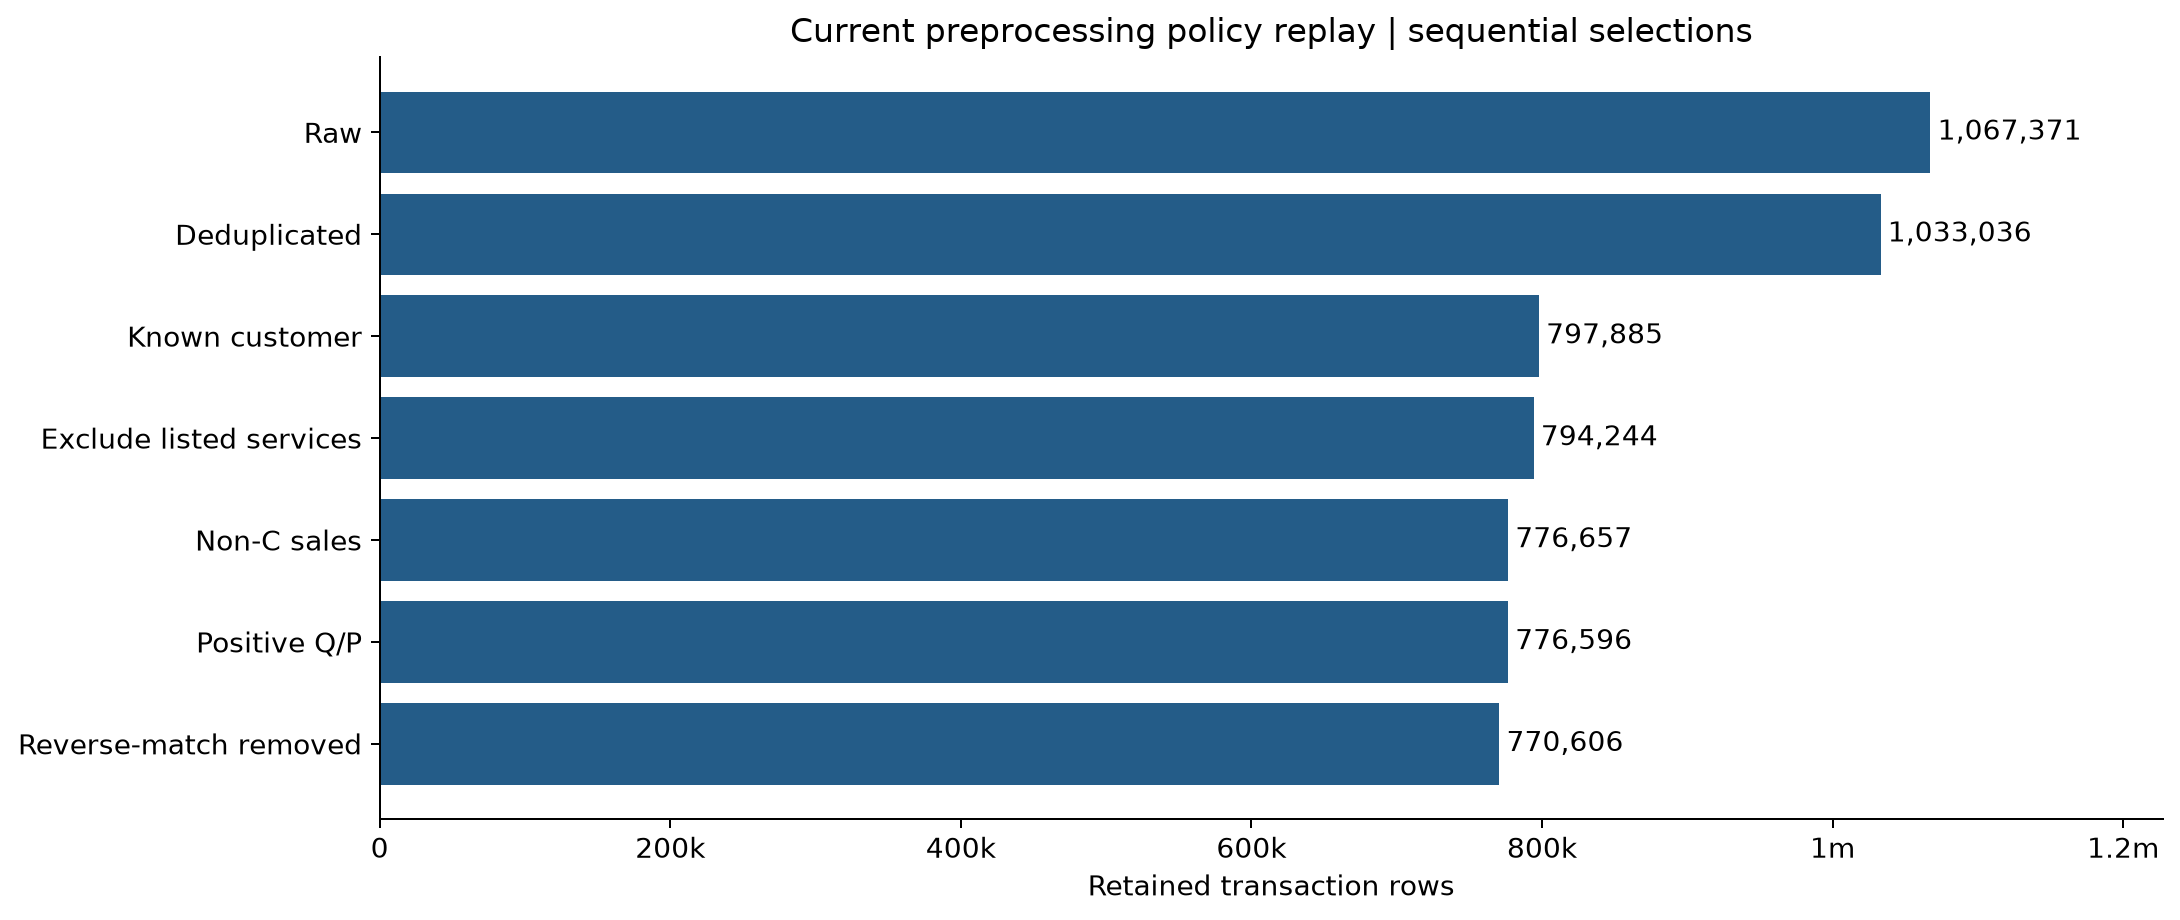

In [11]:
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
trace_df = tables["preprocessing_trace"]
ax.barh(range(len(trace_df)), trace_df.rows_after, color=BLUE)
ax.set_yticks(range(len(trace_df)), ["Raw", "Deduplicated", "Known customer", "Exclude listed services", "Non-C sales", "Positive Q/P", "Reverse-match removed"])
ax.invert_yaxis()
ax.set(xlabel="Retained transaction rows", title="Current preprocessing policy replay | sequential selections")
count_format(ax, "x")
for y, val in enumerate(trace_df.rows_after): ax.text(val+5000,y,f"{val:,}",va="center")
ax.set_xlim(0,len(raw)*1.15)
save(fig, "preprocessing_row_flow.png", "Current preprocessing row flow", "Rows retained at each sequential step; reversal is heuristic", ["preprocessing_trace"])

**Kết quả:** số dòng lần lượt là 1.067.371 → 1.033.036 → 797.885 → 794.244 →
776.657 → 776.596 → 770.606. Tập cuối có 36.414 hóa đơn và 5.839 khách; các bảng/log đã
lưu khớp với kết quả tái hiện. Có 5.990 dòng mua bị loại theo heuristic ghép hủy.

**Giới hạn:** ghép theo khách, mã, giá, lượng đối ứng và thứ tự chưa xác minh hóa đơn gốc
hay hoàn một phần. Với snapshot sớm hơn phải lọc cả mua và hủy trước khi ghép để tránh
thông tin tương lai. Tổng Q×P chính xác là 16.522.106,307 GBP; tổng LineValue làm tròn
là 16.522.106,290 GBP, có 17 dòng Q/P dương làm tròn về 0. Thống nhất cách ghép/làm tròn
với Thuận trước khi gọi đây là tập chính thức.

<a id="eda-description"></a>

## 4. Thống kê mô tả giao dịch

Quantity (đơn vị hàng), Price (GBP/đơn vị), LineValue (GBP/dòng) được thống kê riêng trên thô và tập sau pipeline; xem count, mean, median, Q1/Q3/IQR, P95/P99, min/max, std và skewness.

In [12]:
tables["descriptive_transactions"] = pd.concat([descriptive(raw, ["Quantity", "Price", "LineValue"], "raw_all_rows_including_C"),
                                                    descriptive(clean, ["Quantity", "Price", "LineValue"], "current_pipeline_sales")], ignore_index=True)

table("descriptive_transactions", 20)

**descriptive_transactions** — 6 dòng kết quả.

Bảng giữ trong biến `tables["descriptive_transactions"]`; không xuất CSV trung gian.

,population,variable,count,missing,mean,median,minimum,maximum,std,skewness
0,raw_all_rows_including_C,Quantity,1067371,0,9.9389,3.0000,"-80,995.0000","80,995.0000",172.7058,3.9961
1,raw_all_rows_including_C,Price,1067371,0,4.6494,2.1000,"-53,594.3600","38,970.0000",123.5531,-69.1647
2,raw_all_rows_including_C,LineValue,1067371,0,18.0699,9.9000,"-168,469.6000","168,469.6000",292.4202,-12.4420
3,current_pipeline_sales,Quantity,770606,0,13.1179,6.0000,1.0000,"19,152.0000",73.2267,95.3153
4,current_pipeline_sales,Price,770606,0,2.9159,1.9500,0.0010,649.5000,4.1449,32.7092
5,current_pipeline_sales,LineValue,770606,0,21.4404,11.9000,0.0000,"38,970.0000",81.2054,167.7270


**Kết quả:** Quantity thô có trung vị 3,
P99 = 100; Price có trung vị
2.1 GBP/đơn vị. Cần đọc mean cùng median và các phân vị
vì đuôi phân phối lớn; trung bình đơn lẻ không mô tả đủ một giao dịch điển hình.

**Phạm vi:** LineValue của tập thô là Q×P có dấu; LineValue trong processed được làm tròn
hai chữ số. Không gọi tổng giá trị thô là doanh thu thuần khi chưa chốt quy tắc.
Không lấy trung bình Customer ID vì đó là định danh.

<a id="eda-time"></a>

## 5. Thời gian

EDA thô bao gồm C, dòng âm, dòng trùng và thiếu khách hàng. Đếm Invoice duy nhất theo tháng; tổng Quantity×Price gọi là tổng giá trị dòng có dấu, chưa xác nhận là doanh thu thuần. Biểu đồ ghi đơn vị dòng/hóa đơn.

**monthly** — 25 dòng kết quả.

Bảng giữ trong biến `tables["monthly"]`; không xuất CSV trung gian.

,month,rows,invoices,customers,signed_line_value_gbp,date_min,date_max,c_invoices,non_c_invoices,calendar_coverage_partial
0,2009-12,45228,2330,1045,"799,847.1100",2009-12-01 07:45:00,2009-12-23 16:58:00,401,1929,False
1,2010-01,31555,1633,786,"624,032.8920",2010-01-04 09:24:00,2010-01-31 16:02:00,300,1333,False
2,2010-02,29388,1969,807,"533,091.4260",2010-02-01 08:13:00,2010-02-28 16:16:00,240,1729,False
3,2010-03,41511,2367,1111,"765,848.7610",2010-03-01 08:38:00,2010-03-31 17:53:00,407,1960,False
4,2010-04,34057,1892,998,"590,580.4320",2010-04-01 07:49:00,2010-04-30 17:33:00,304,1588,False
5,2010-05,35323,2418,1062,"615,322.8300",2010-05-02 10:22:00,2010-05-30 15:58:00,407,2011,False
6,2010-06,39983,2216,1095,"679,786.6100",2010-06-01 09:02:00,2010-06-30 17:38:00,357,1859,False
7,2010-07,33383,2017,988,"575,236.3600",2010-07-01 08:39:00,2010-07-30 17:08:00,344,1673,False
8,2010-08,33306,1877,964,"656,776.3400",2010-08-01 10:04:00,2010-08-31 17:44:00,273,1604,False
9,2010-09,42091,2375,1202,"853,650.4310",2010-09-01 09:22:00,2010-09-30 20:11:00,371,2004,False


**weekday_hour** — 86 dòng kết quả.

Bảng giữ trong biến `tables["weekday_hour"]`; không xuất CSV trung gian.

,weekday,hour,rows,invoices
0,0,7,163,20
1,0,8,3003,185
2,0,9,15570,620
3,0,10,17886,968
4,0,11,19562,980
5,0,12,26151,1295
6,0,13,27240,1224
7,0,14,23066,1046
8,0,15,23430,1117
9,0,16,17447,749


Đang xem 12/86 dòng. Sau Run All, dùng `tables["weekday_hour"]` để xem đầy đủ.

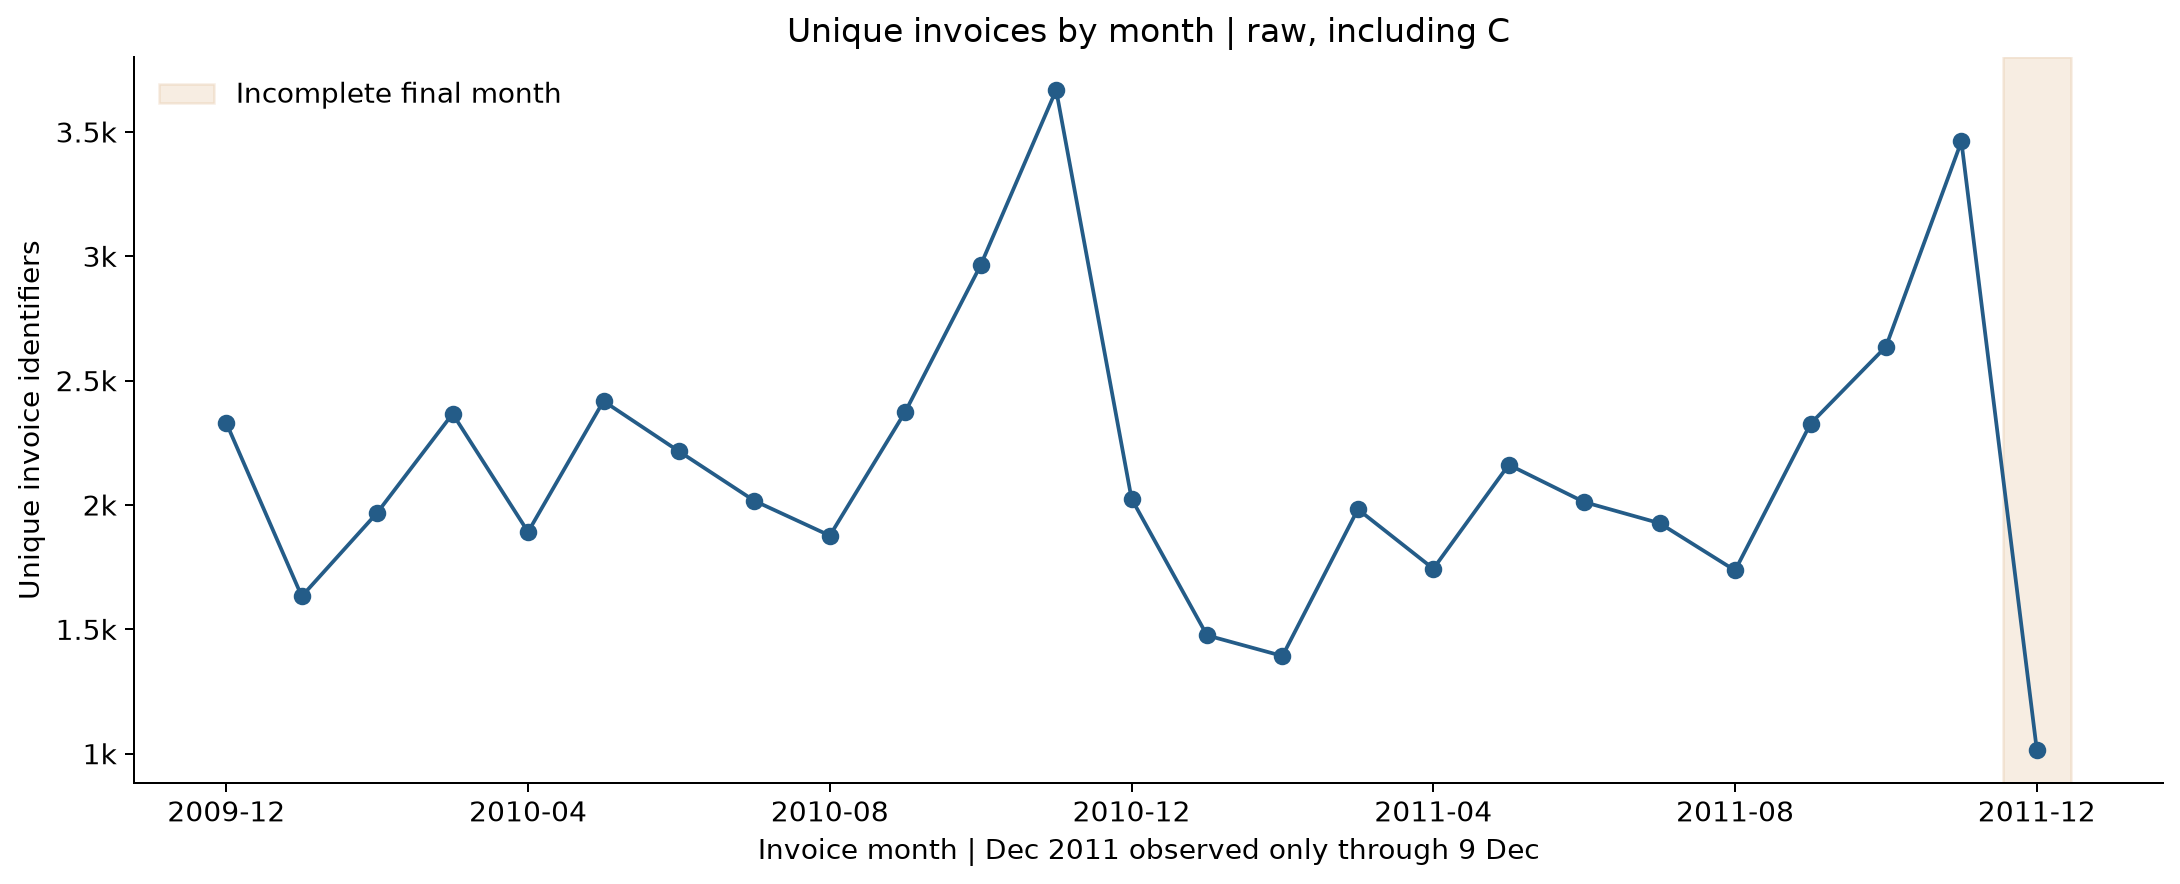

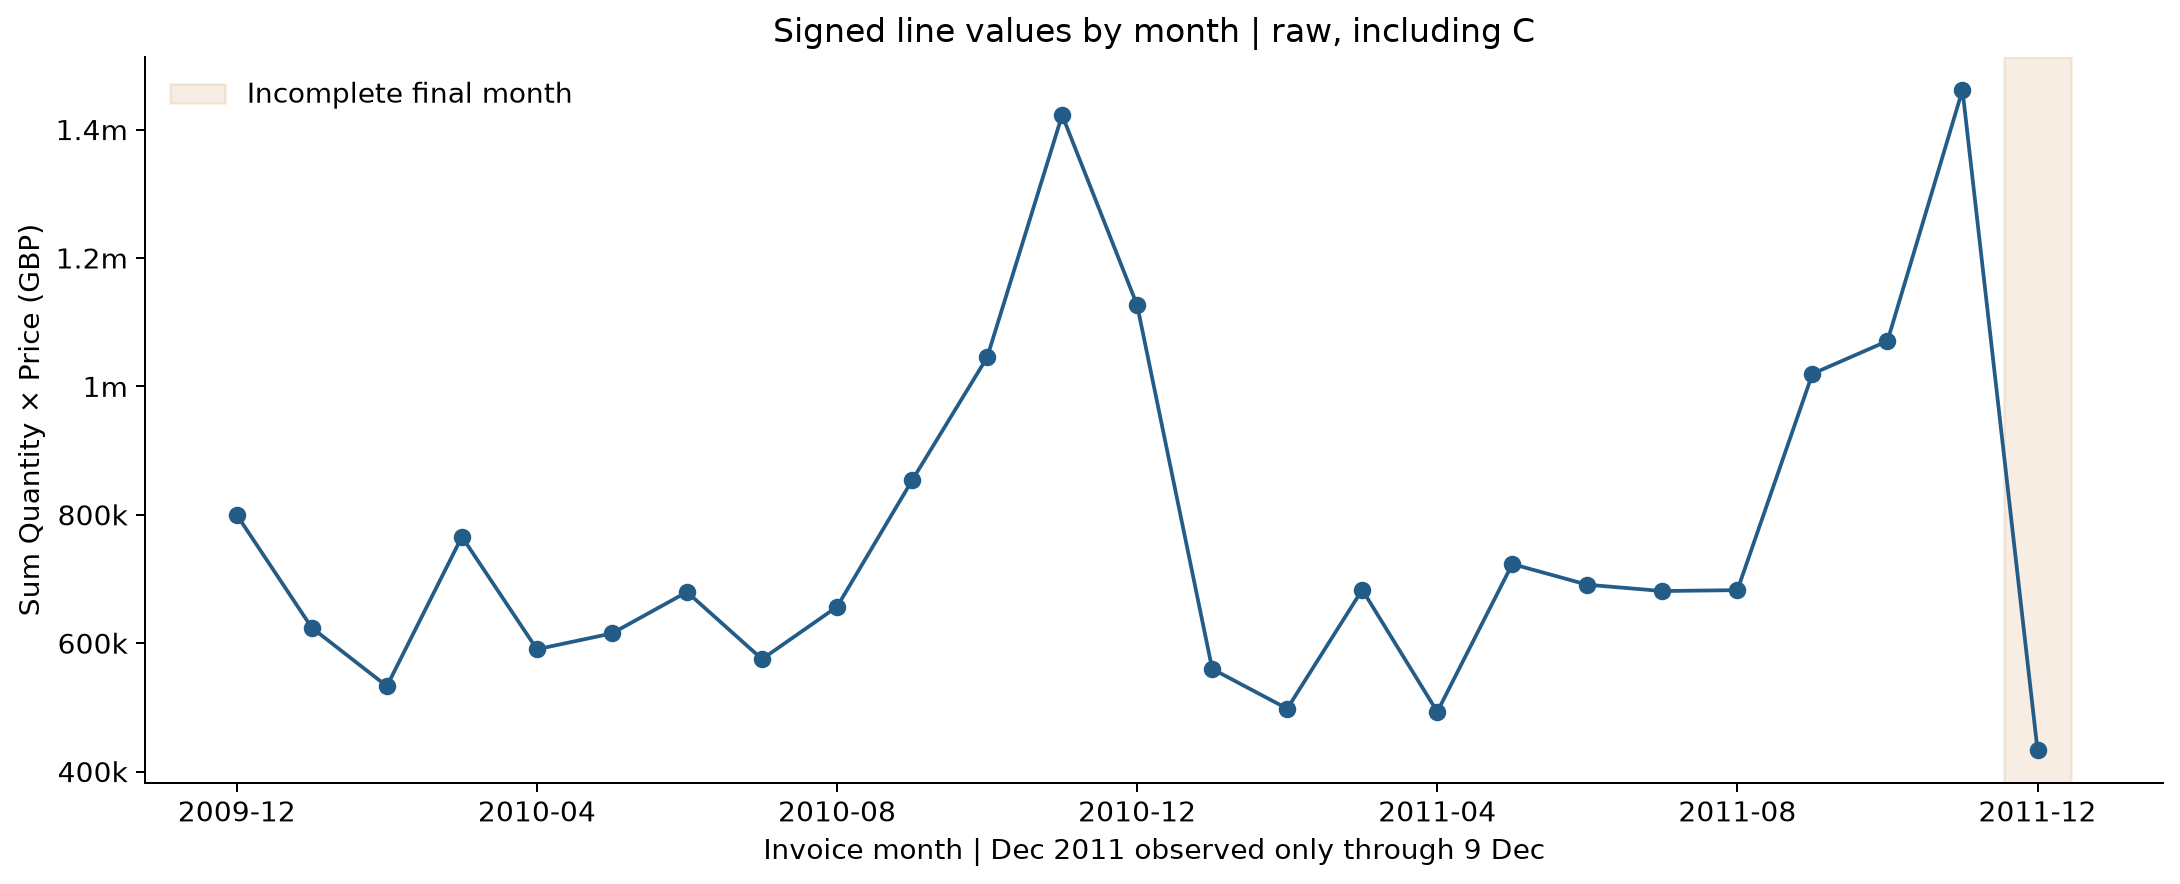

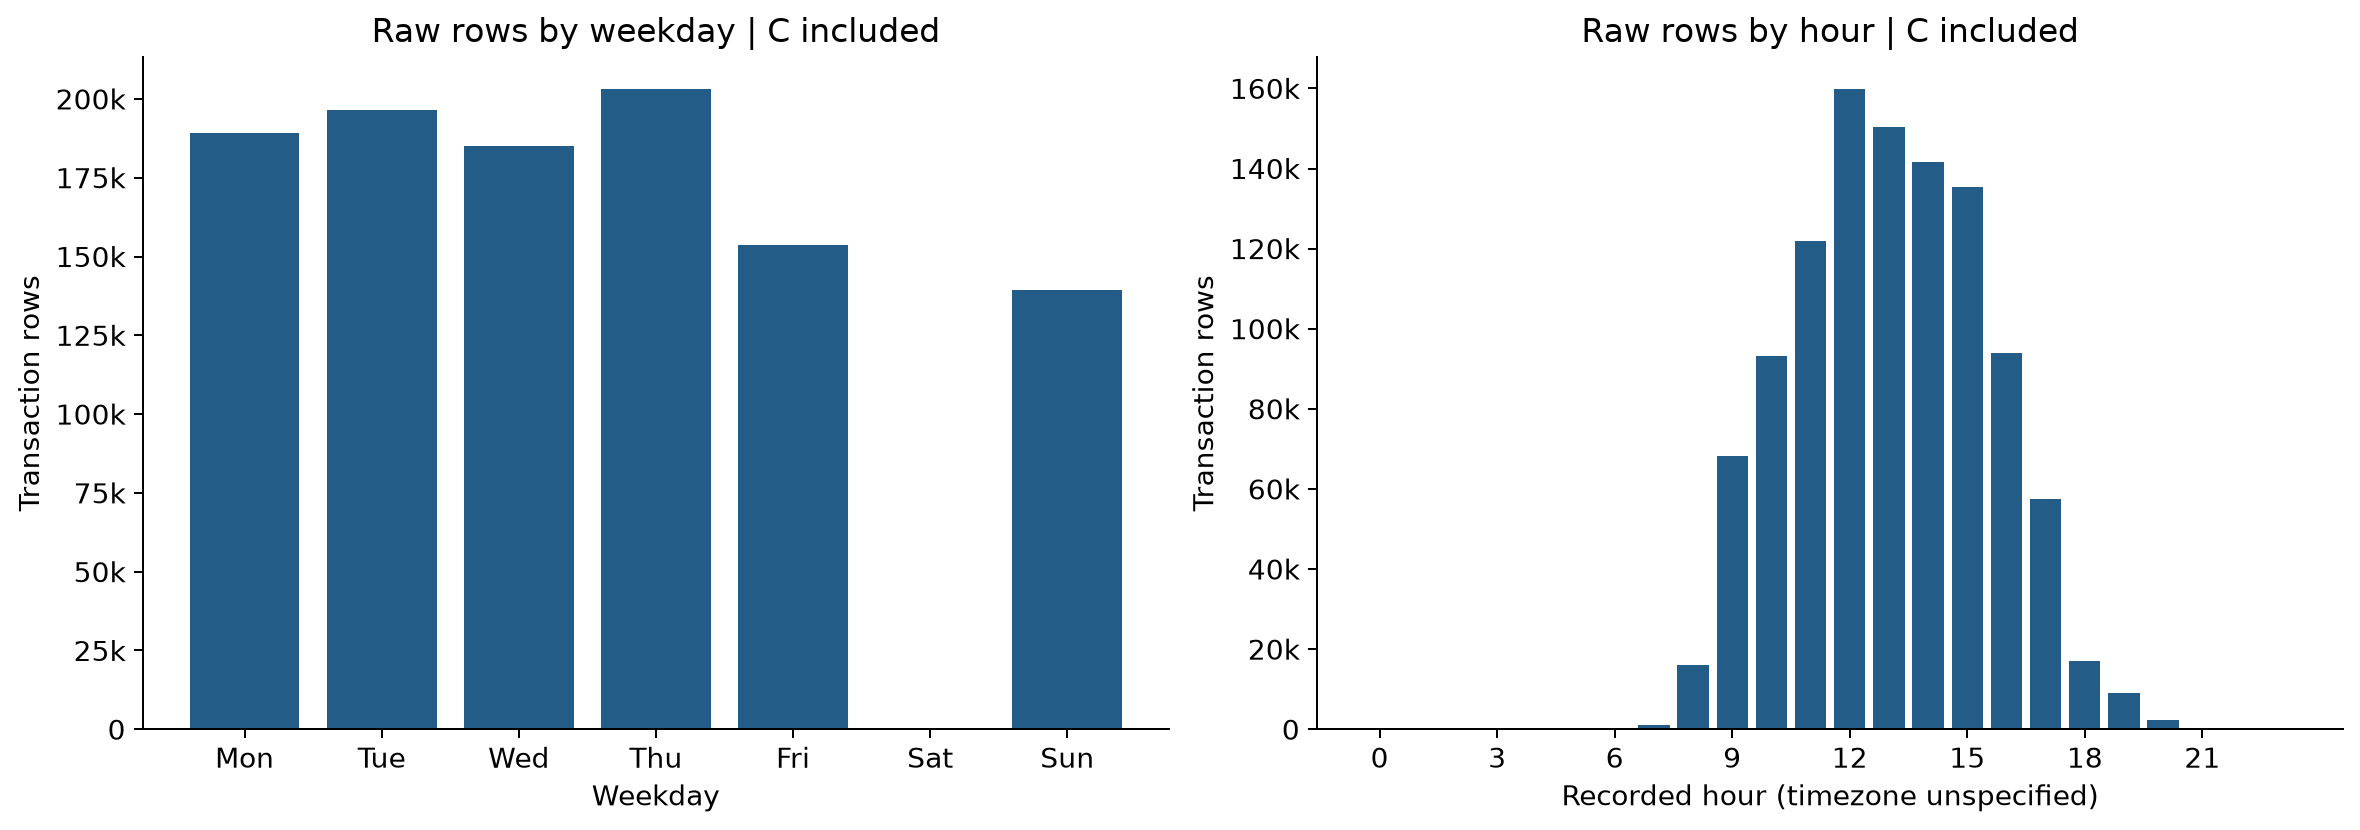

In [13]:
raw["month"] = raw.InvoiceDate.dt.to_period("M").astype(str)
tables["monthly"] = raw.groupby("month").agg(rows=("Invoice", "size"), invoices=("Invoice", "nunique"), customers=("Customer ID", "nunique"),
                                               signed_line_value_gbp=("LineValue", "sum"), date_min=("InvoiceDate", "min"), date_max=("InvoiceDate", "max")).reset_index()
c_month = raw.loc[raw.is_c].groupby("month").Invoice.nunique()
tables["monthly"]["c_invoices"] = tables["monthly"].month.map(c_month).fillna(0).astype(int)
tables["monthly"]["non_c_invoices"] = tables["monthly"].invoices - tables["monthly"].c_invoices
tables["monthly"]["calendar_coverage_partial"] = tables["monthly"].month.isin([raw.InvoiceDate.min().strftime("%Y-%m"), raw.InvoiceDate.max().strftime("%Y-%m")])
tables["monthly"].loc[tables["monthly"].month.eq(raw.InvoiceDate.min().strftime("%Y-%m")), "calendar_coverage_partial"] = raw.InvoiceDate.min().day != 1
raw["weekday"] = raw.InvoiceDate.dt.day_of_week
raw["hour"] = raw.InvoiceDate.dt.hour
tables["weekday_hour"] = raw.groupby(["weekday", "hour"]).agg(rows=("Invoice", "size"), invoices=("Invoice", "nunique")).reset_index()

table("monthly", 30)
table("weekday_hour", 12)

monthly = tables["monthly"]
dates = pd.to_datetime(monthly.month)
ticks = list(range(0, len(dates), 4)) + [len(dates)-1]
ticks = sorted(set(ticks))
for col, name, title, unit in [("invoices", "invoices_by_month.png", "Unique invoices by month | raw, including C", "Unique invoice identifiers"),
                                ("signed_line_value_gbp", "signed_line_value_by_month.png", "Signed line values by month | raw, including C", "Sum Quantity × Price (GBP)")]:
    fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
    ax.plot(range(len(monthly)), monthly[col], marker="o", color=BLUE)
    ax.set_xticks(ticks, monthly.month.iloc[ticks])
    ax.set(xlabel="Invoice month | Dec 2011 observed only through 9 Dec", ylabel=unit, title=title)
    ax.axvspan(len(monthly)-1.45, len(monthly)-.55, color=ORANGE, alpha=.13, label="Incomplete final month")
    ax.legend(loc="upper left", frameon=False)
    count_format(ax)
    save(fig, name, title, "Raw transaction rows; C included; final month incomplete", ["monthly"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
days = raw.groupby("weekday").size().reindex(range(7), fill_value=0)
hours = raw.groupby("hour").size().reindex(range(24), fill_value=0)
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], days, color=BLUE)
axes[0].set(title="Raw rows by weekday | C included", xlabel="Weekday", ylabel="Transaction rows")
axes[1].bar(hours.index, hours, color=BLUE)
axes[1].set(title="Raw rows by hour | C included", xlabel="Recorded hour (timezone unspecified)", ylabel="Transaction rows", xticks=range(0,24,3))
for ax in axes: count_format(ax)
save(fig, "transactions_by_weekday_hour.png", "Raw transaction rows by weekday and hour", "Raw rows including C, all dates", ["weekday_hour"])

**Kết quả:** có 25 tháng quan sát. Tháng 12/2011 chỉ có 25.526 dòng và 1.015 chứng từ,
đến ngày 09/12; tổng giá trị dòng có dấu là 433.686,01 GBP. Vì thiếu phần còn lại của
tháng, mức thấp ở điểm cuối không được diễn giải như suy giảm của cả tháng.

**Ý nghĩa:** các biểu đồ giữ C, trùng và dòng chưa có khách. Đỉnh hoặc khoảng trống theo
thứ/giờ mô tả lịch ghi nhận trong nguồn, chưa chỉ ra nguyên nhân hay mùa vụ dài hạn.
Khi thực nghiệm theo thời gian, chọn các cửa sổ đủ độ dài và nêu rõ tháng biên.

<a id="eda-country"></a>

## 6. Quốc gia

Tách số dòng, Invoice duy nhất trong từng quốc gia, khách hàng có mã và tổng giá trị dòng. Khách hàng có nhiều quốc gia có thể được đếm ở nhiều nhóm, nên không mặc định tổng khách hàng nhóm bằng tổng duy nhất toàn bộ.

**countries** — 43 dòng kết quả.

Bảng giữ trong biến `tables["countries"]`; không xuất CSV trung gian.

,Country,rows,invoices,customers,signed_line_value_gbp,rows_denominator,rows_pct,invoices_denominator,invoices_pct,customers_denominator,customers_pct,signed_value_denominator_gbp,signed_value_pct
40,United Kingdom,981330,49108,5410,"16,382,583.8970",1067371,91.9390,53628,91.5716,5942,91.0468,"19,287,250.5680",84.9400
11,EIRE,17866,806,5,"615,519.5500",1067371,1.6738,53628,1.5029,5942,0.0841,"19,287,250.5680",3.1913
15,Germany,17624,1095,107,"417,988.5610",1067371,1.6512,53628,2.0418,5942,1.8007,"19,287,250.5680",2.1672
14,France,14330,746,95,"328,191.8000",1067371,1.3426,53628,1.3911,5942,1.5988,"19,287,250.5680",1.7016
26,Netherlands,5140,250,23,"548,524.9500",1067371,0.4816,53628,0.4662,5942,0.3871,"19,287,250.5680",2.8440
34,Spain,3811,188,41,"91,859.4800",1067371,0.3570,53628,0.3506,5942,0.6900,"19,287,250.5680",0.4763
36,Switzerland,3189,123,22,"99,728.7600",1067371,0.2988,53628,0.2294,5942,0.3702,"19,287,250.5680",0.5171
3,Belgium,3123,183,29,"63,574.4900",1067371,0.2926,53628,0.3412,5942,0.4881,"19,287,250.5680",0.3296
30,Portugal,2620,124,24,"53,136.8000",1067371,0.2455,53628,0.2312,5942,0.4039,"19,287,250.5680",0.2755
0,Australia,1913,117,15,"167,129.0700",1067371,0.1792,53628,0.2182,5942,0.2524,"19,287,250.5680",0.8665


Đang xem 12/43 dòng. Sau Run All, dùng `tables["countries"]` để xem đầy đủ.

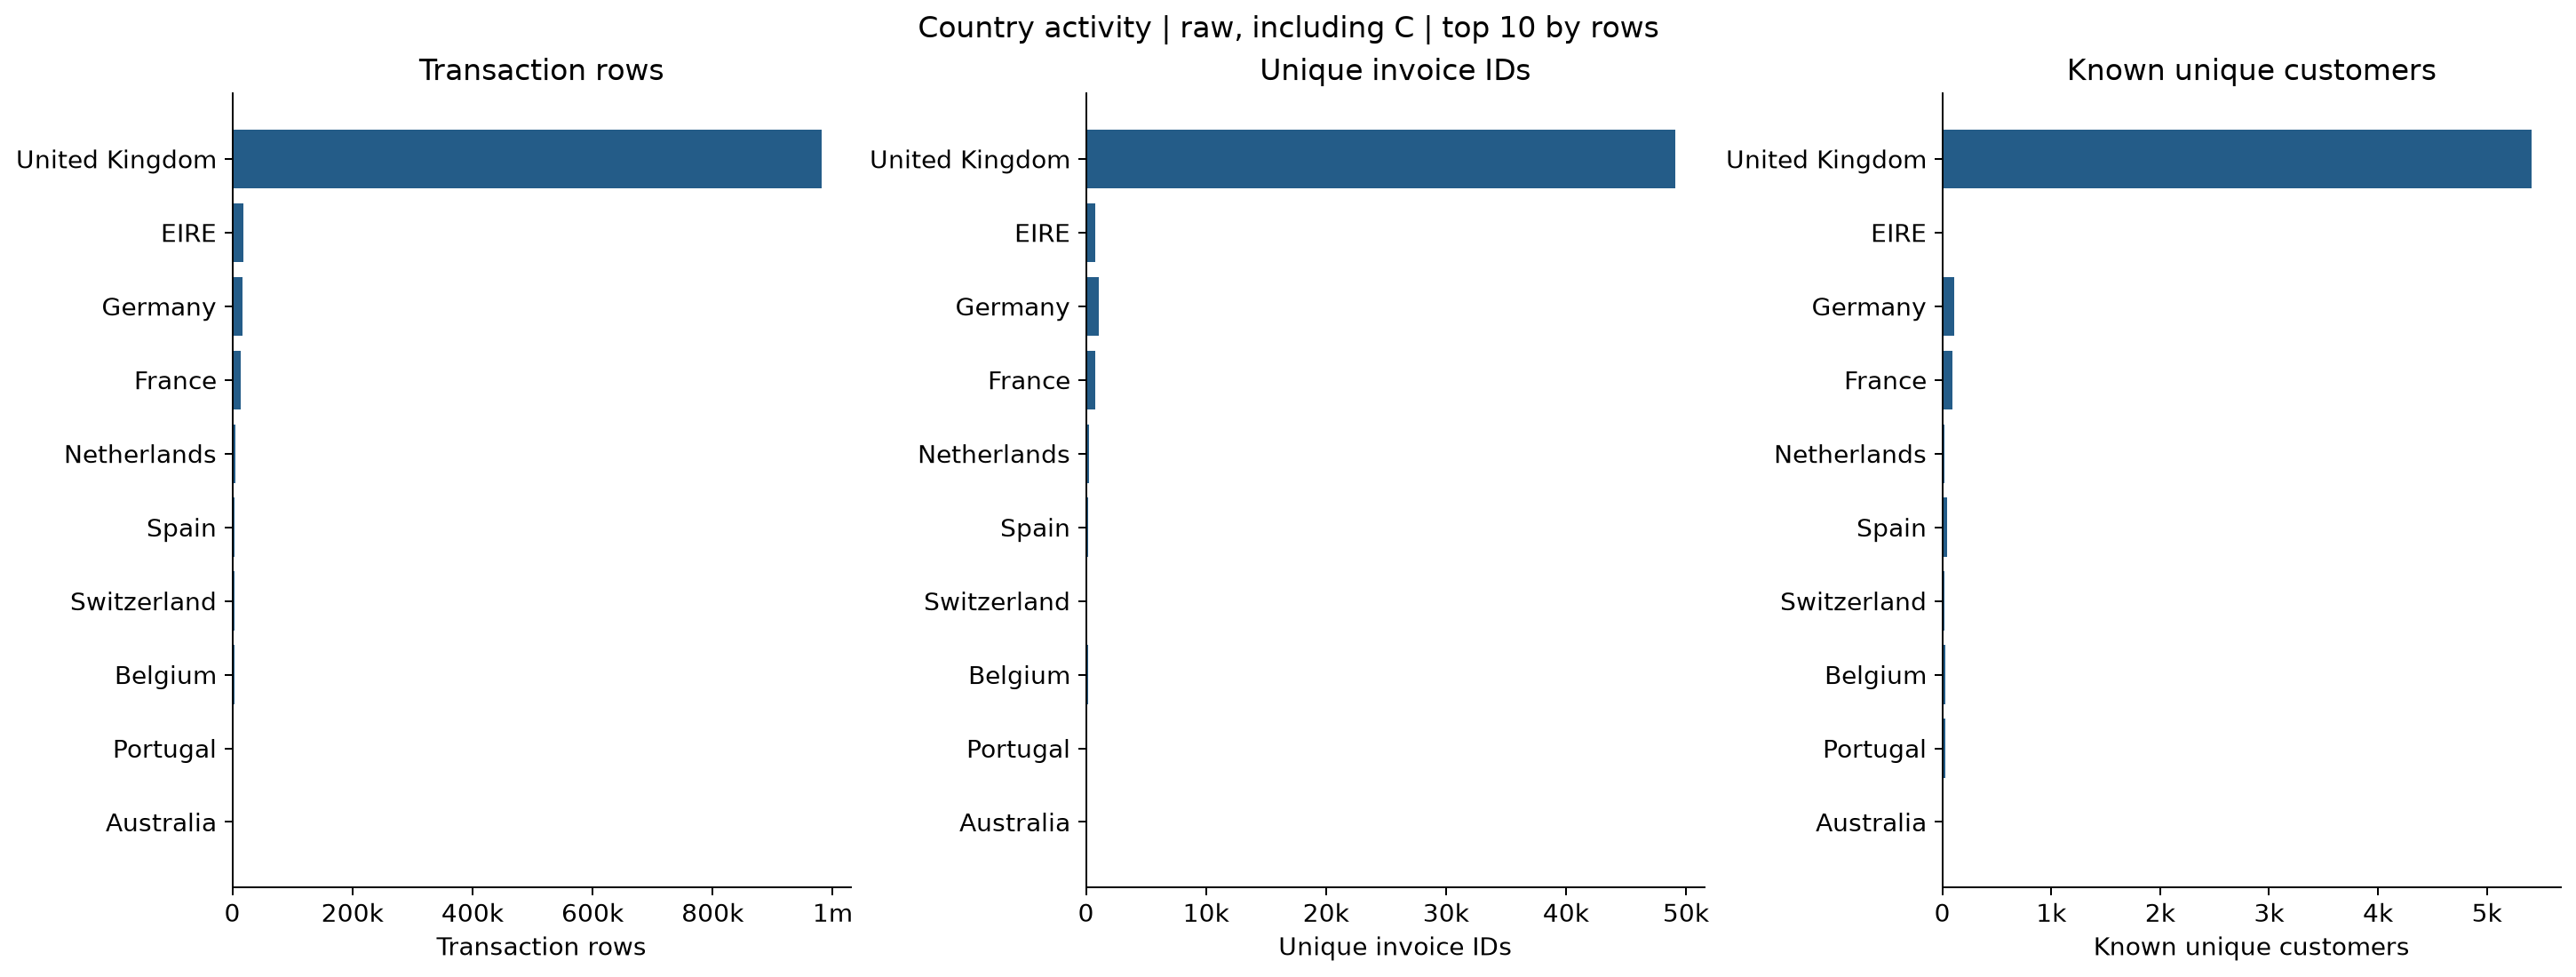

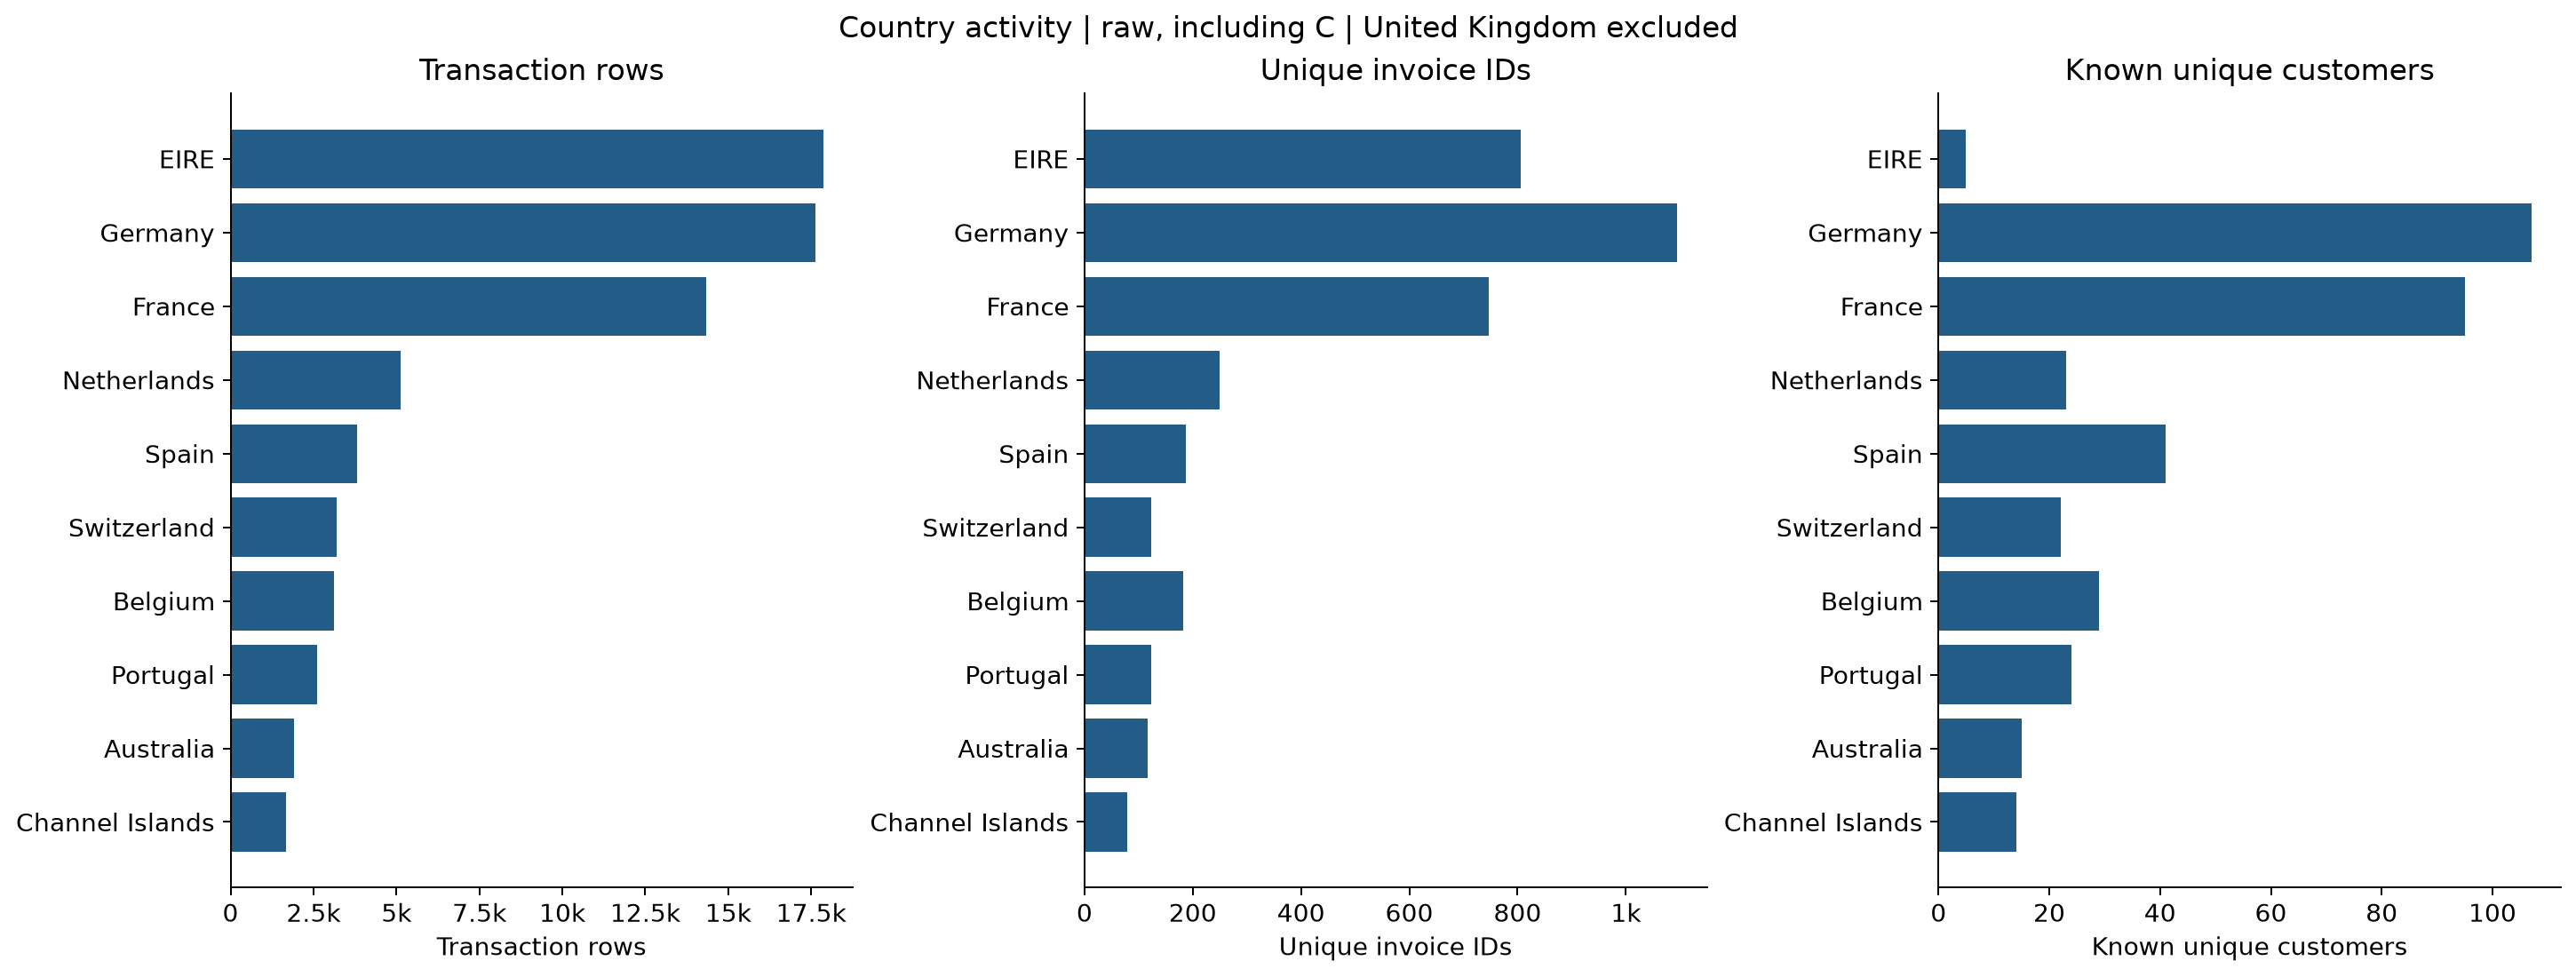

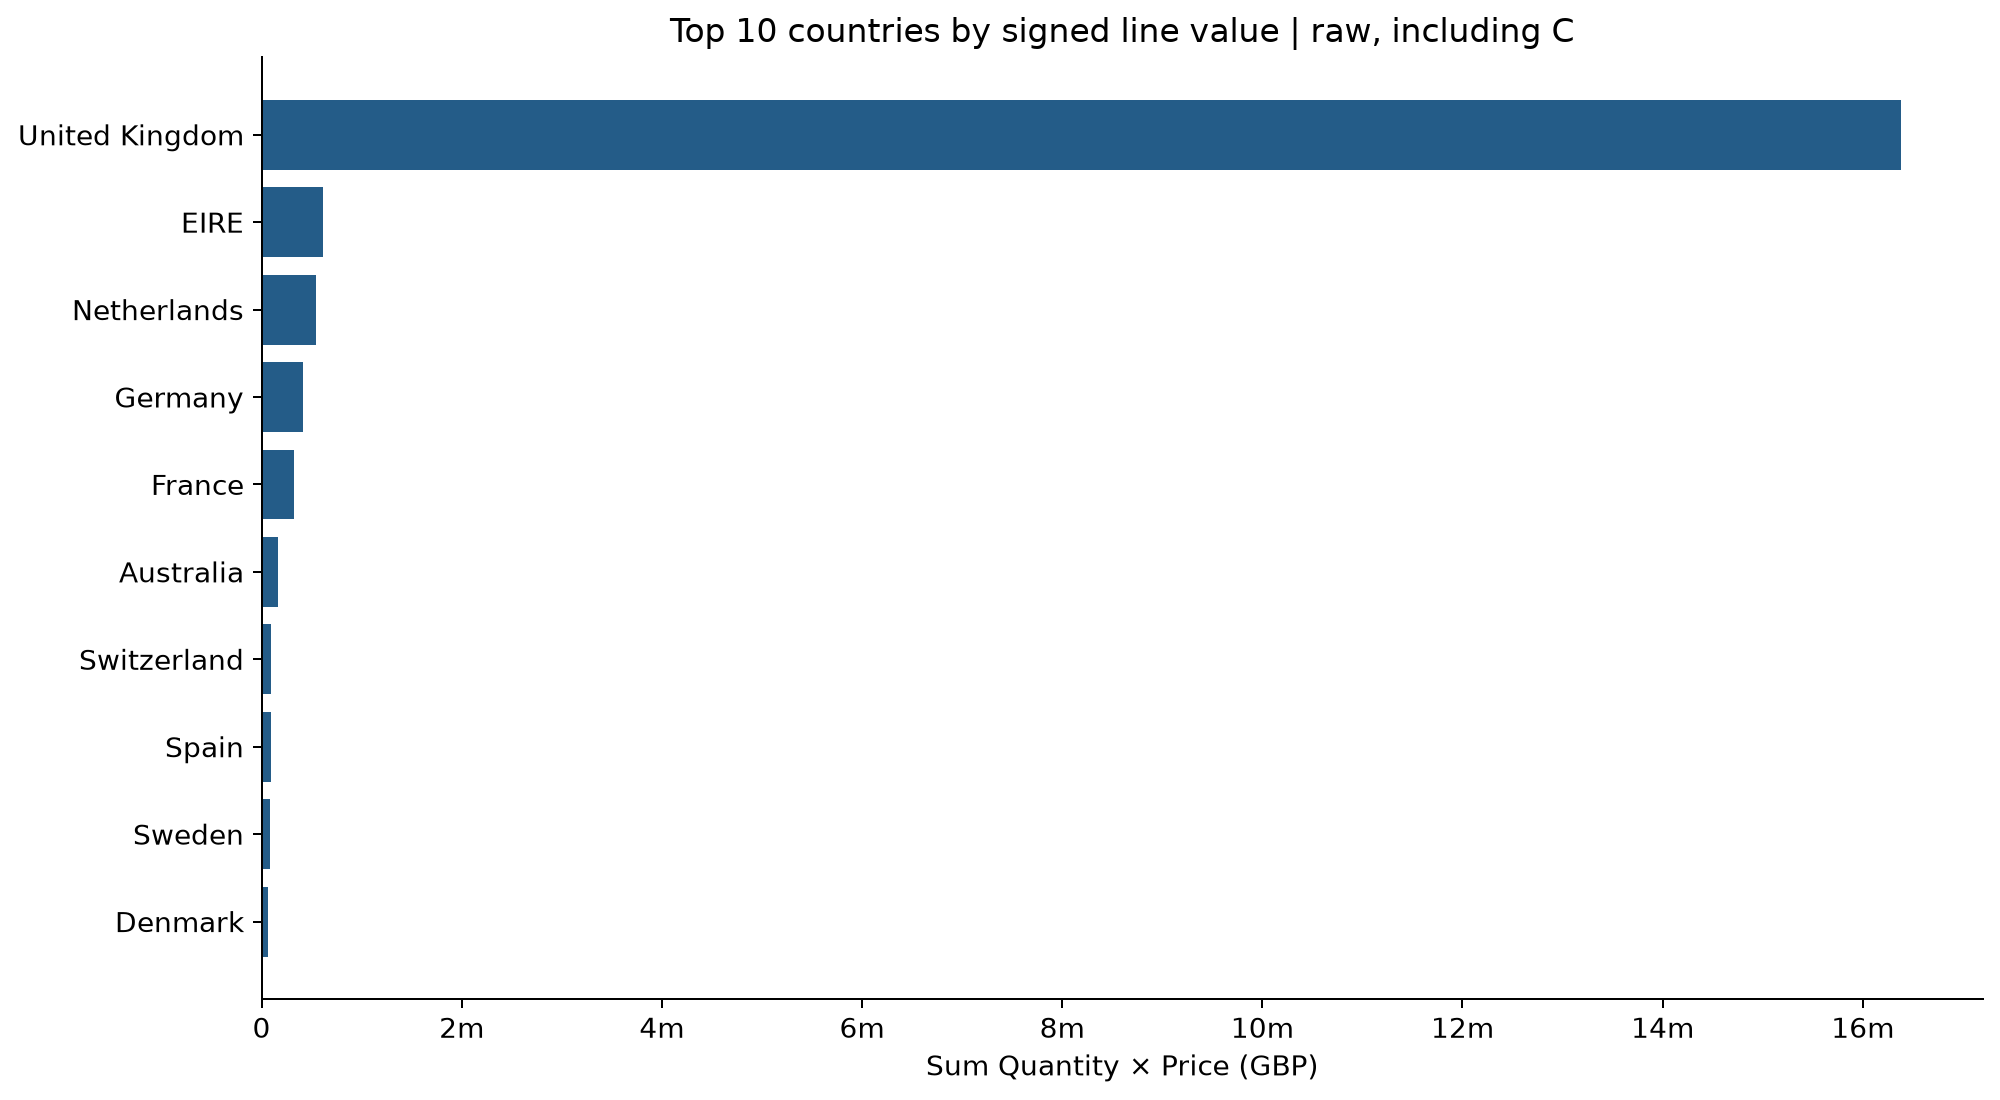

In [14]:
country = raw.groupby("Country", dropna=False).agg(rows=("Invoice", "size"), invoices=("Invoice", "nunique"), customers=("Customer ID", "nunique"),
                                                           signed_line_value_gbp=("LineValue", "sum")).reset_index()
for measure, denominator in [("rows", len(raw)), ("invoices", raw.Invoice.nunique()), ("customers", raw["Customer ID"].nunique())]:
    country[f"{measure}_denominator"] = denominator
    country[f"{measure}_pct"] = country[measure] / denominator * 100
country["signed_value_denominator_gbp"] = raw.LineValue.sum()
country["signed_value_pct"] = country.signed_line_value_gbp / raw.LineValue.sum() * 100
tables["countries"] = country.sort_values("rows", ascending=False)
tables["c_document_audit"] = audit_c_documents(raw, window_start=WINDOW_START, reference_date=REFERENCE_DATE)

table("countries", 12)

country = tables["countries"]
for exclude, filename in [(False, "country_activity.png"), (True, "country_activity_excluding_uk.png")]:
    selected = country.loc[country.Country.ne("United Kingdom")] if exclude else country
    selected = selected.nlargest(10, "rows").sort_values("rows")
    fig, axes = plt.subplots(1, 3, figsize=(16, 6), layout="constrained")
    for ax, measure, label in zip(axes, ["rows", "invoices", "customers"], ["Transaction rows", "Unique invoice IDs", "Known unique customers"]):
        ax.barh(selected.Country, selected[measure], color=BLUE)
        ax.set(xlabel=label, title=label)
        count_format(ax, "x")
    fig.suptitle("Country activity | raw, including C" + (" | United Kingdom excluded" if exclude else " | top 10 by rows"))
    save(fig, filename, "Country activity" + (" excluding UK" if exclude else " including UK"), "Raw rows/invoice IDs/known customers; customer country sets may overlap", ["countries"])
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
selected = country.nlargest(10, "signed_line_value_gbp").sort_values("signed_line_value_gbp")
ax.barh(selected.Country, selected.signed_line_value_gbp, color=BLUE)
ax.set(xlabel="Sum Quantity × Price (GBP)", title="Top 10 countries by signed line value | raw, including C")
count_format(ax, "x")
save(fig, "signed_line_value_by_country.png", "Signed line value by country", "Raw signed line values including C; not asserted net revenue", ["countries"])

**Kết quả:** United Kingdom chiếm 981,330/1,067,371 dòng
(91.94%) trong 43 nhãn quốc gia. Hình bỏ UK giúp quan sát
các thị trường còn lại, nhưng cần đọc cùng hình toàn bộ.

**Ý nghĩa:** quy mô dòng, số hóa đơn và số khách đo các mặt khác nhau. Một khách có thể
ở nhiều nhóm quốc gia nên không cộng các nhóm để thay số khách duy nhất toàn nguồn.
Nhãn Unspecified được giữ nguyên. Mức tập trung này cần được xét khi diễn giải các cụm.

<a id="eda-behavior"></a>

## 7. Hành vi khách hàng

Dùng tập sau pipeline, đổi tên CustomerID thành Customer ID khi gọi features.py; một khách một dòng. Giá trị mua là tổng Q×P các dòng mua được cung cấp, AOV là tổng đó chia số Invoice; C và SERVICE_CODES bị loại theo pipeline.

Building exploratory customer features and RFM (no model)...


**customer_summary** — 1 dòng kết quả.

Bảng giữ trong biến `tables["customer_summary"]`; không xuất CSV trung gian.

,customers,invoices,single_invoice_customers,single_invoice_pct,denominator_customers,missing_purchase_gap,multi_timestamp_orders,orders_value_gbp,exact_purchase_value_gbp,spearman_orders_value
0,5839,36414,1613,27.6246,5839,1613,64,"16,522,106.3070","16,522,106.3070",0.8580


**customer_behavior** — 5,839 dòng kết quả.

[CSV bàn giao](../../experiments/eda_rebuild/tables/customer_behavior.csv)

,Customer ID,n_orders,total_purchase_value,avg_order_value,n_stock_codes_candidate,avg_purchase_gap_days,return_rate
0,12346,2,169.3600,84.6800,24,118.0312,NaN
1,12347,8,"4,921.5300",615.1912,126,57.4377,NaN
2,12348,5,"1,658.4000",331.6800,24,90.7316,NaN
3,12349,3,"3,678.6900","1,226.2300",137,285.4274,NaN
4,12350,1,294.4000,294.4000,16,NaN,NaN
5,12351,1,300.9300,300.9300,21,NaN,NaN
6,12352,9,"1,609.2100",178.8011,68,44.5223,NaN
7,12353,2,406.7600,203.3800,23,204.2104,NaN
8,12354,1,"1,079.4000","1,079.4000",58,NaN,NaN
9,12355,2,947.6100,473.8050,35,353.0764,NaN


Đang xem 10/5,839 dòng. Sau Run All, dùng `tables["customer_behavior"]` để xem đầy đủ.

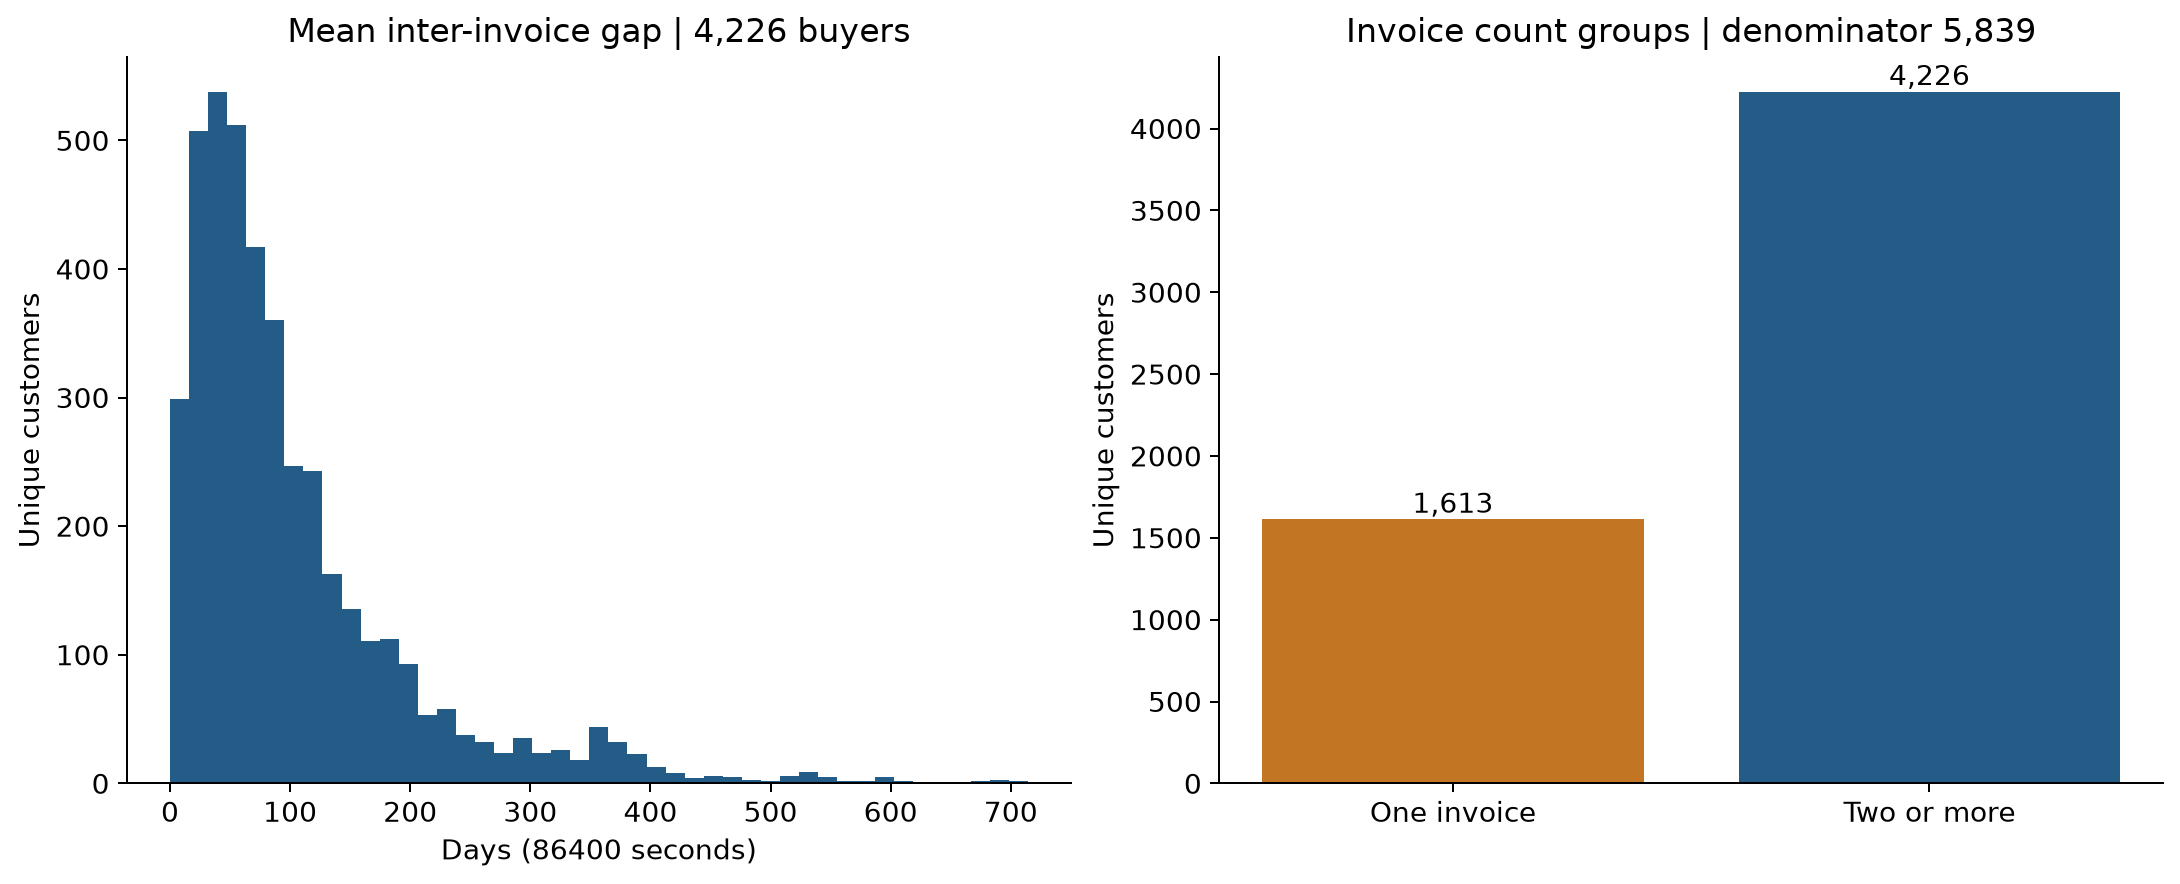

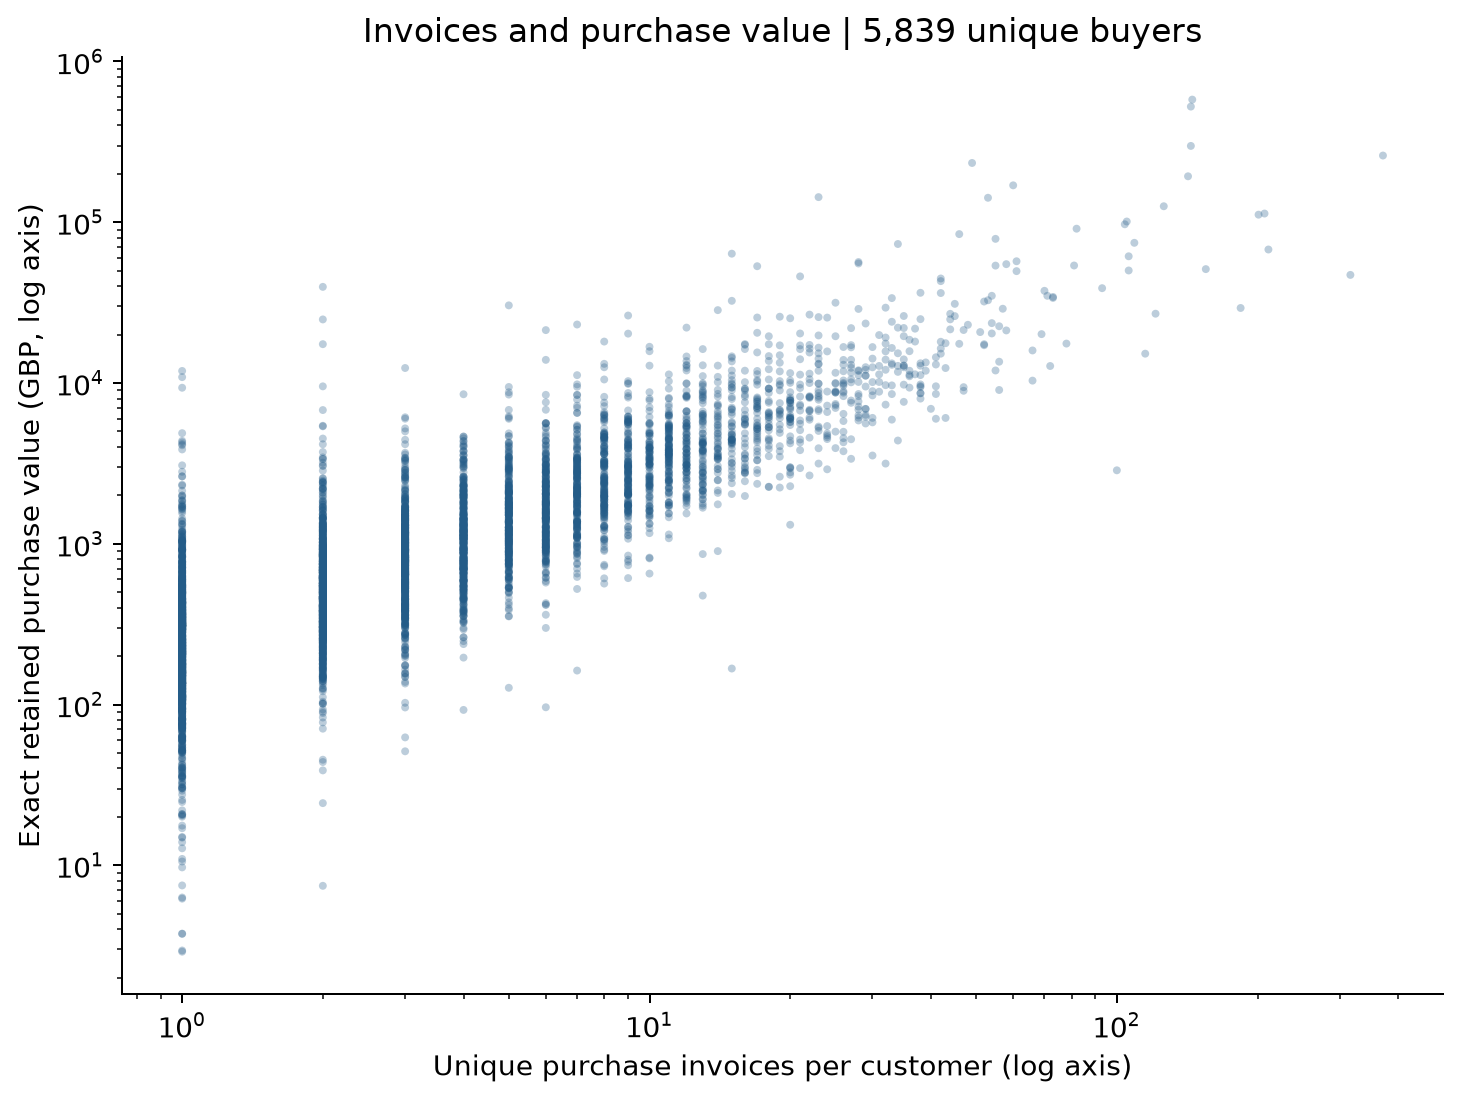

In [15]:
print("Building exploratory customer features and RFM (no model)...", flush=True)
purchase = clean.rename(columns={"CustomerID": "Customer ID"}).copy()
behavior = build_customer_behavior_features(purchase, window_start=WINDOW_START, reference_date=REFERENCE_DATE,
                                           stock_code_roles=None, invoice_time_policy="earliest", include_optional=True)
orders = aggregate_purchase_orders(purchase, window_start=WINDOW_START, reference_date=REFERENCE_DATE, invoice_time_policy="earliest")
purchase["Customer ID"] = identifier(purchase["Customer ID"])
totals = purchase.groupby("Customer ID").agg(total_purchase_value_rounded=("LineValue", "sum"), total_quantity_candidate=("Quantity", "sum"), n_stock_codes_candidate=("StockCode", "nunique"))
totals["total_purchase_value"] = (purchase.Quantity*purchase.Price).groupby(purchase["Customer ID"]).sum()
behavior = behavior.merge(totals, on="Customer ID", validate="one_to_one")
behavior["avg_quantity_per_order_candidate"] = behavior.total_quantity_candidate / behavior.n_orders
behavior["candidate_scope"] = "Codes retained by current service exclusion; not verified product catalog"
assert behavior["Customer ID"].is_unique
assert behavior.n_transaction_rows.sum() == len(clean)
assert behavior.n_orders.sum() == len(orders)
assert behavior.return_rate.isna().all()
assert behavior.loc[behavior.n_orders.eq(1), "avg_purchase_gap_days"].isna().all()
assert behavior.n_distinct_products.isna().all()
assert np.isclose(behavior.total_purchase_value.sum(), clean_exact_total)
assert np.allclose(behavior.avg_order_value * behavior.n_orders, behavior.total_purchase_value)
tables["customer_behavior"] = behavior
behavior_numeric = ["n_orders", "total_purchase_value", "avg_order_value", "n_stock_codes_candidate", "total_quantity_candidate", "avg_quantity_per_order_candidate", "avg_purchase_gap_days", "observed_tenure_days"]
tables["descriptive_customers"] = descriptive(behavior, behavior_numeric, "experimental_customers_from_current_pipeline")
singles = int(behavior.n_orders.eq(1).sum())
tables["customer_summary"] = pd.DataFrame([dict(customers=len(behavior), invoices=len(orders), single_invoice_customers=singles,
                                                single_invoice_pct=100*singles/len(behavior), denominator_customers=len(behavior),
                                                missing_purchase_gap=int(behavior.avg_purchase_gap_days.isna().sum()),
                                                multi_timestamp_orders=int(orders.n_timestamps.gt(1).sum()),
                                                orders_value_gbp=orders.order_value.sum(), exact_purchase_value_gbp=clean_exact_total,
                                                spearman_orders_value=behavior[["n_orders", "total_purchase_value"]].corr(method="spearman").iloc[0, 1])])

table("customer_summary", 20)
table("customer_behavior", 10)

fig, axes=plt.subplots(1,2,figsize=(12,4.8),layout="constrained")
gaps=behavior.avg_purchase_gap_days.dropna()
axes[0].hist(gaps,bins=45,color=BLUE)
axes[0].set(title=f"Mean inter-invoice gap | {len(gaps):,} buyers",xlabel="Days (86400 seconds)",ylabel="Unique customers")
axes[1].bar(["One invoice","Two or more"],[singles,len(behavior)-singles],color=[ORANGE,BLUE])
axes[1].set(title=f"Invoice count groups | denominator {len(behavior):,}",ylabel="Unique customers")
for i,val in enumerate([singles,len(behavior)-singles]):axes[1].text(i,val,f"{val:,}",ha="center",va="bottom")
save(fig,"customer_purchase_gaps.png","Customer purchase gaps and one-invoice share","Experimental buyers; gap undefined for single-invoice buyers",["customer_summary","customer_behavior"])

fig,ax=plt.subplots(figsize=(8,6),layout="constrained")
ax.scatter(behavior.n_orders,behavior.total_purchase_value,s=10,alpha=.3,color=BLUE,edgecolors="none")
ax.set(xscale="log",yscale="log",xlabel="Unique purchase invoices per customer (log axis)",ylabel="Exact retained purchase value (GBP, log axis)",title=f"Invoices and purchase value | {len(behavior):,} unique buyers")
save(fig,"customer_orders_vs_value.png","Customer invoice count versus purchase value","One dot per experimental buyer; correlation not causality",["customer_summary","customer_behavior"])

**Kết quả:** bảng hành vi có đúng một dòng cho mỗi trong 5.839 khách.
1,613 khách (27.62%) chỉ có một hóa đơn,
nên khoảng cách mua chưa xác định và được giữ NaN. Trung vị giá trị mua là 851,01 GBP,
thấp hơn trung bình 2.829,61 GBP, cho thấy ảnh hưởng của đuôi lớn.

**Ý nghĩa:** Spearman giữa số đơn và tổng mua là 0.858,
nhưng tổng giá trị vốn có thành phần tăng theo số đơn; đây không phải quan hệ nhân quả.
Số StockCode/Quantity ứng viên chưa được gọi là sản phẩm đã xác minh.

<a id="eda-features"></a>

## 8. Khảo sát đặc trưng thủ công

Đối chiếu công thức/đơn vị/cửa sổ với src/features.py và Form 2 cũ. Không ghi đè khảo sát thô cũ trong experiments/form2_manual_behavior_raw_survey/.

In [16]:
definitions = [
    ("avg_order_value", "mean(sum(Quantity*Price) by (Customer ID,Invoice))", "GBP/invoice", "None for retained buyers", "Can support clusters; skewness/redundancy with M/F", "Exact multiplication; rounding differs from stored LineValue"),
    ("n_distinct_products", "nunique(StockCode classified product), only when classification complete", "verified products/customer", "All missing: no approved stock_code_roles supplied", "Not ready", "Cần nhóm xác nhận product catalog"),
    ("avg_quantity_per_order", "sum(classified product Quantity)/n_orders", "product units/invoice", "All missing: product mapping unavailable", "Not ready", "Cần nhóm xác nhận product catalog"),
    ("avg_purchase_gap_days", "mean(diff(earliest timestamp for each Invoice))", "days (86400 seconds)", "One-invoice customers have no observed interval", "Can use with missingness policy", "Cần nhóm xác nhận earliest timestamp and single-order handling"),
    ("total_quantity", "sum(classified product Quantity)", "product units/customer", "All missing: product mapping unavailable", "Not ready", "Cần nhóm xác nhận product catalog"),
    ("observed_tenure_days", "(reference_date - first observed purchase)/1 day", "days", "None for retained buyers", "Consider unequal observation exposure", "Observed history, not true customer age"),
    ("return_rate", "Unresolved verified return denominator and linkage", "undefined", "All missing by design, never zero-filled", "Not ready", "Cần nhóm xác nhận return source and linkage"),
    ("n_stock_codes_candidate", "nunique(retained StockCode)", "unverified codes/customer", "None", "Exploratory sensitivity only", "Not n_distinct_products"),
    ("total_quantity_candidate", "sum(Quantity for retained purchase rows)", "unverified units/customer", "None", "Exploratory sensitivity only", "Not verified product units")]
tables["feature_definitions"] = pd.DataFrame(definitions, columns=["feature", "formula", "unit", "missing_reason", "clustering_readiness", "confirmation_or_limit"])
tables["feature_definitions"]["window_start"] = WINDOW_START
tables["feature_definitions"]["reference_date_exclusive"] = REFERENCE_DATE
profile_columns = [x[0] for x in definitions] + ["n_orders", "total_purchase_value", "avg_quantity_per_order_candidate"]
tables["feature_profile"] = descriptive(behavior, profile_columns, "experimental_customer_features")

table("feature_definitions", 20)
table("feature_profile", 25)

**feature_definitions** — 9 dòng kết quả.

Bảng giữ trong biến `tables["feature_definitions"]`; không xuất CSV trung gian.

,feature,formula,unit,missing_reason,clustering_readiness,confirmation_or_limit,window_start,reference_date_exclusive
0,avg_order_value,"mean(sum(Quantity*Price) by (Customer ID,Invoice))",GBP/invoice,None for retained buyers,Can support clusters; skewness/redundancy with M/F,Exact multiplication; rounding differs from stored LineValue,2009-12-01,2011-12-10
1,n_distinct_products,"nunique(StockCode classified product), only when classification complete",verified products/customer,All missing: no approved stock_code_roles supplied,Not ready,Cần nhóm xác nhận product catalog,2009-12-01,2011-12-10
2,avg_quantity_per_order,sum(classified product Quantity)/n_orders,product units/invoice,All missing: product mapping unavailable,Not ready,Cần nhóm xác nhận product catalog,2009-12-01,2011-12-10
3,avg_purchase_gap_days,mean(diff(earliest timestamp for each Invoice)),days (86400 seconds),One-invoice customers have no observed interval,Can use with missingness policy,Cần nhóm xác nhận earliest timestamp and single-order handling,2009-12-01,2011-12-10
4,total_quantity,sum(classified product Quantity),product units/customer,All missing: product mapping unavailable,Not ready,Cần nhóm xác nhận product catalog,2009-12-01,2011-12-10
5,observed_tenure_days,(reference_date - first observed purchase)/1 day,days,None for retained buyers,Consider unequal observation exposure,"Observed history, not true customer age",2009-12-01,2011-12-10
6,return_rate,Unresolved verified return denominator and linkage,undefined,"All missing by design, never zero-filled",Not ready,Cần nhóm xác nhận return source and linkage,2009-12-01,2011-12-10
7,n_stock_codes_candidate,nunique(retained StockCode),unverified codes/customer,None,Exploratory sensitivity only,Not n_distinct_products,2009-12-01,2011-12-10
8,total_quantity_candidate,sum(Quantity for retained purchase rows),unverified units/customer,None,Exploratory sensitivity only,Not verified product units,2009-12-01,2011-12-10


**feature_profile** — 12 dòng kết quả.

Bảng giữ trong biến `tables["feature_profile"]`; không xuất CSV trung gian.

,population,variable,count,missing,mean,median,minimum,maximum,std,skewness
0,experimental_customer_features,avg_order_value,5839,0,363.3452,274.7600,2.9000,"19,809.7500",533.5357,16.6121
1,experimental_customer_features,n_distinct_products,0,5839,NaN,NaN,NaN,NaN,NaN,NaN
2,experimental_customer_features,avg_quantity_per_order,0,5839,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,experimental_customer_features,avg_purchase_gap_days,4226,1613,103.6875,72.9825,0.0000,714.1521,99.2076,2.1559
4,experimental_customer_features,total_quantity,0,5839,NaN,NaN,NaN,NaN,NaN,NaN
5,experimental_customer_features,observed_tenure_days,5839,0,474.0426,529.4597,0.4889,738.6771,223.1790,-0.6147
6,experimental_customer_features,return_rate,0,5839,NaN,NaN,NaN,NaN,NaN,NaN
7,experimental_customer_features,n_stock_codes_candidate,5839,0,81.8794,45.0000,1,2507,116.0781,6.1794
8,experimental_customer_features,total_quantity_candidate,5839,0,"1,731.2454",480.0000,1,365114,"8,592.0930",23.1578
9,experimental_customer_features,n_orders,5839,0,6.2363,3.0000,1,371,12.6765,11.9753


**Kết quả:** AOV, khoảng cách mua và observed tenure tính được theo cửa sổ đã chọn.
Ba chỉ số sản phẩm chính thức và return_rate đều thiếu cho 5.839 khách vì chưa có mapping
sản phẩm được duyệt và nguồn hoàn trả đã xác minh. NaN ở đây không phải số 0 quan sát được.

**Đề xuất:** dùng các biến ứng viên với tên/phạm vi riêng để khảo sát; chốt danh mục mã,
xử lý khách một đơn và lựa chọn biến trước khi phân cụm. Observed tenure chỉ đo lịch sử
quan sát được, không phải tuổi thực của quan hệ khách hàng.

<a id="eda-outliers"></a>

## 9. Tóm tắt phân phối, ngoại lệ và RFM

Các phép tính và hình được giữ để tái lập bằng chứng của báo cáo đã hoàn thành.
Notebook v2 trình bày riêng nội dung này và vẫn tự đọc dữ liệu khi chạy độc lập.
Ngưỡng IQR chỉ gắn cờ thống kê, không tự xóa dòng hay khách hàng.

**outlier_transactions** — 6 dòng kết quả.

Bảng giữ trong biến `tables["outlier_transactions"]`; không xuất CSV trung gian.

,population,variable,count,median,q1,q3,iqr,p95,p99,maximum,outside_iqr,outside_iqr_pct
0,raw_all_rows_including_C,Quantity,1067371,3.0000,1.0000,10.0000,9.0000,30.0000,100.0000,"80,995.0000",116489,10.9136
1,raw_all_rows_including_C,Price,1067371,2.1000,1.2500,4.1500,2.9000,9.9500,18.0000,"38,970.0000",68105,6.3806
2,raw_all_rows_including_C,LineValue,1067371,9.9000,3.7500,17.7000,13.9500,59.5000,180.0000,"168,469.6000",90922,8.5183
3,current_pipeline_sales,Quantity,770606,6.0000,2.0000,12.0000,10.0000,36.0000,128.0000,"19,152.0000",50292,6.5263
4,current_pipeline_sales,Price,770606,1.9500,1.2500,3.7500,2.5000,8.5000,12.7500,649.5000,61844,8.0254
5,current_pipeline_sales,LineValue,770606,11.9000,4.9500,19.5000,14.5500,67.2000,195.6000,"38,970.0000",62772,8.1458


**extreme_rows** — 30 dòng kết quả.

Bảng giữ trong biến `tables["extreme_rows"]`; không xuất CSV trung gian.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,LineValue,variable,direction
0,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.0800,"16,446.0000",United Kingdom,Year 2010-2011,"-168,469.6000",Quantity,smallest
1,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.0400,"12,346.0000",United Kingdom,Year 2010-2011,"-77,183.6000",Quantity,smallest
2,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.0000,NaN,United Kingdom,Year 2009-2010,-0.0000,Quantity,smallest
3,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0000,NaN,United Kingdom,Year 2010-2011,-0.0000,Quantity,smallest
4,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0000,NaN,United Kingdom,Year 2010-2011,-0.0000,Quantity,smallest
5,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.0800,"16,446.0000",United Kingdom,Year 2010-2011,"168,469.6000",Quantity,largest
6,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.0400,"12,346.0000",United Kingdom,Year 2010-2011,"77,183.6000",Quantity,largest
7,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,915.2000",Quantity,largest
8,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,296.0000",Quantity,largest
9,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,296.0000",Quantity,largest


Đang xem 18/30 dòng. Sau Run All, dùng `tables["extreme_rows"]` để xem đầy đủ.

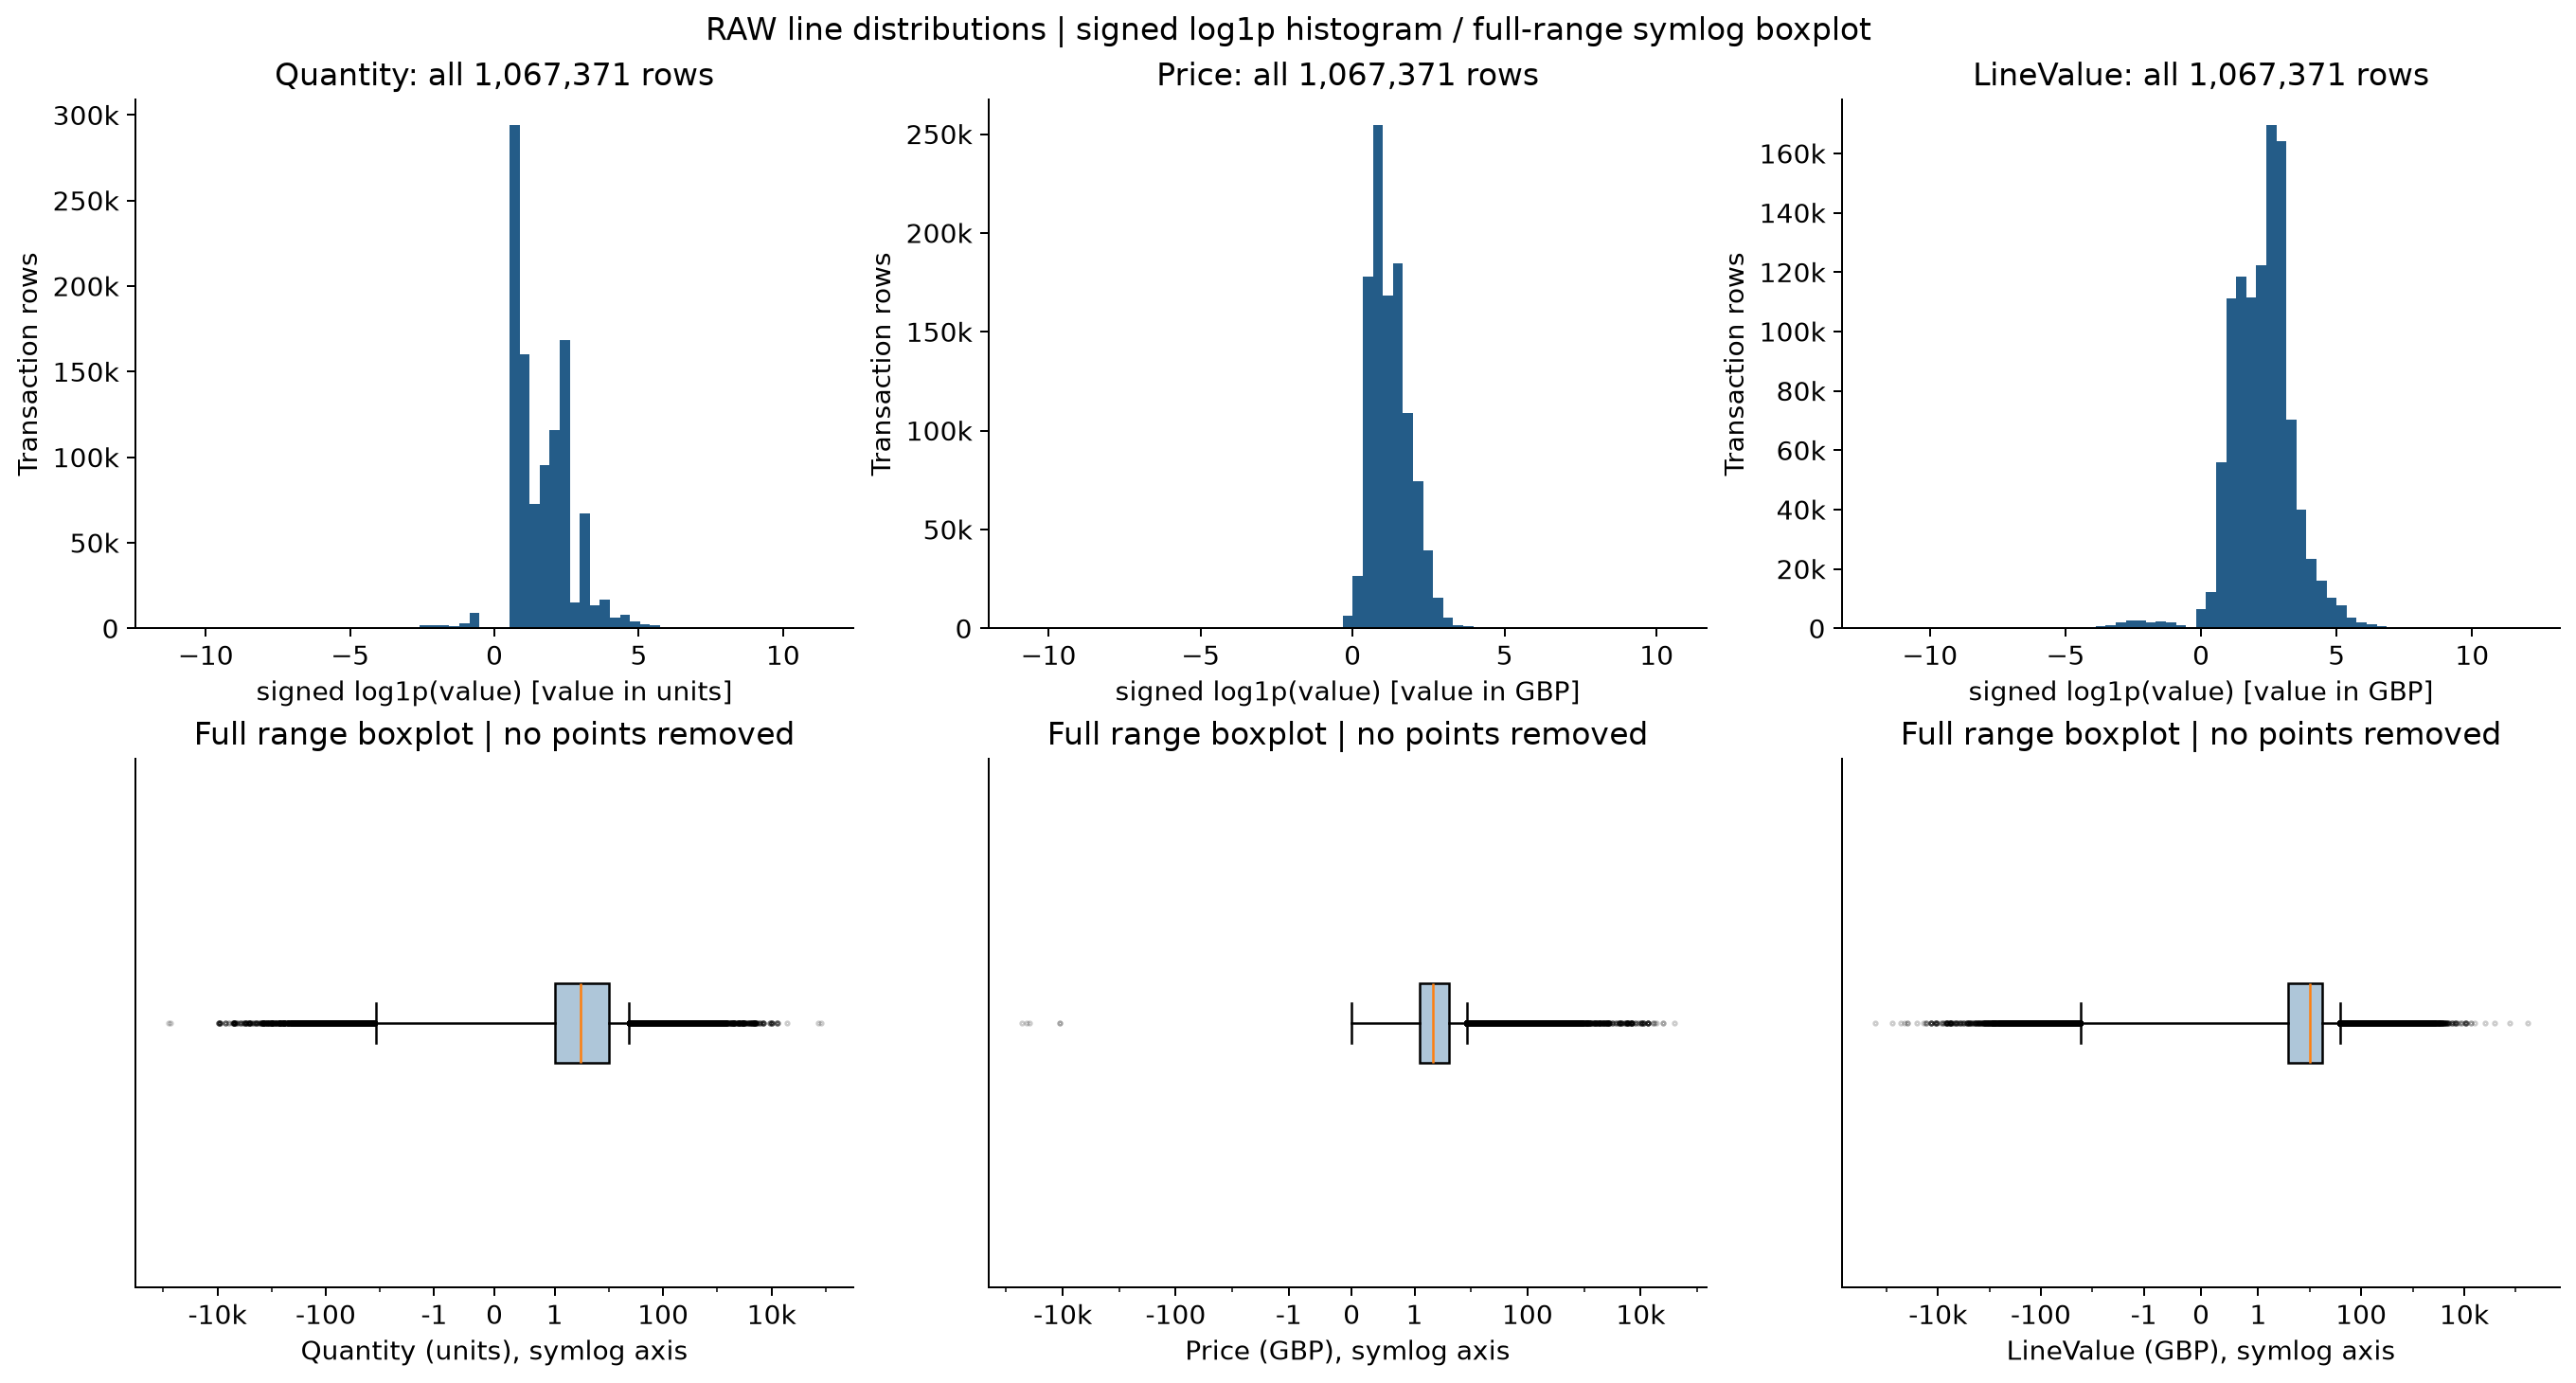

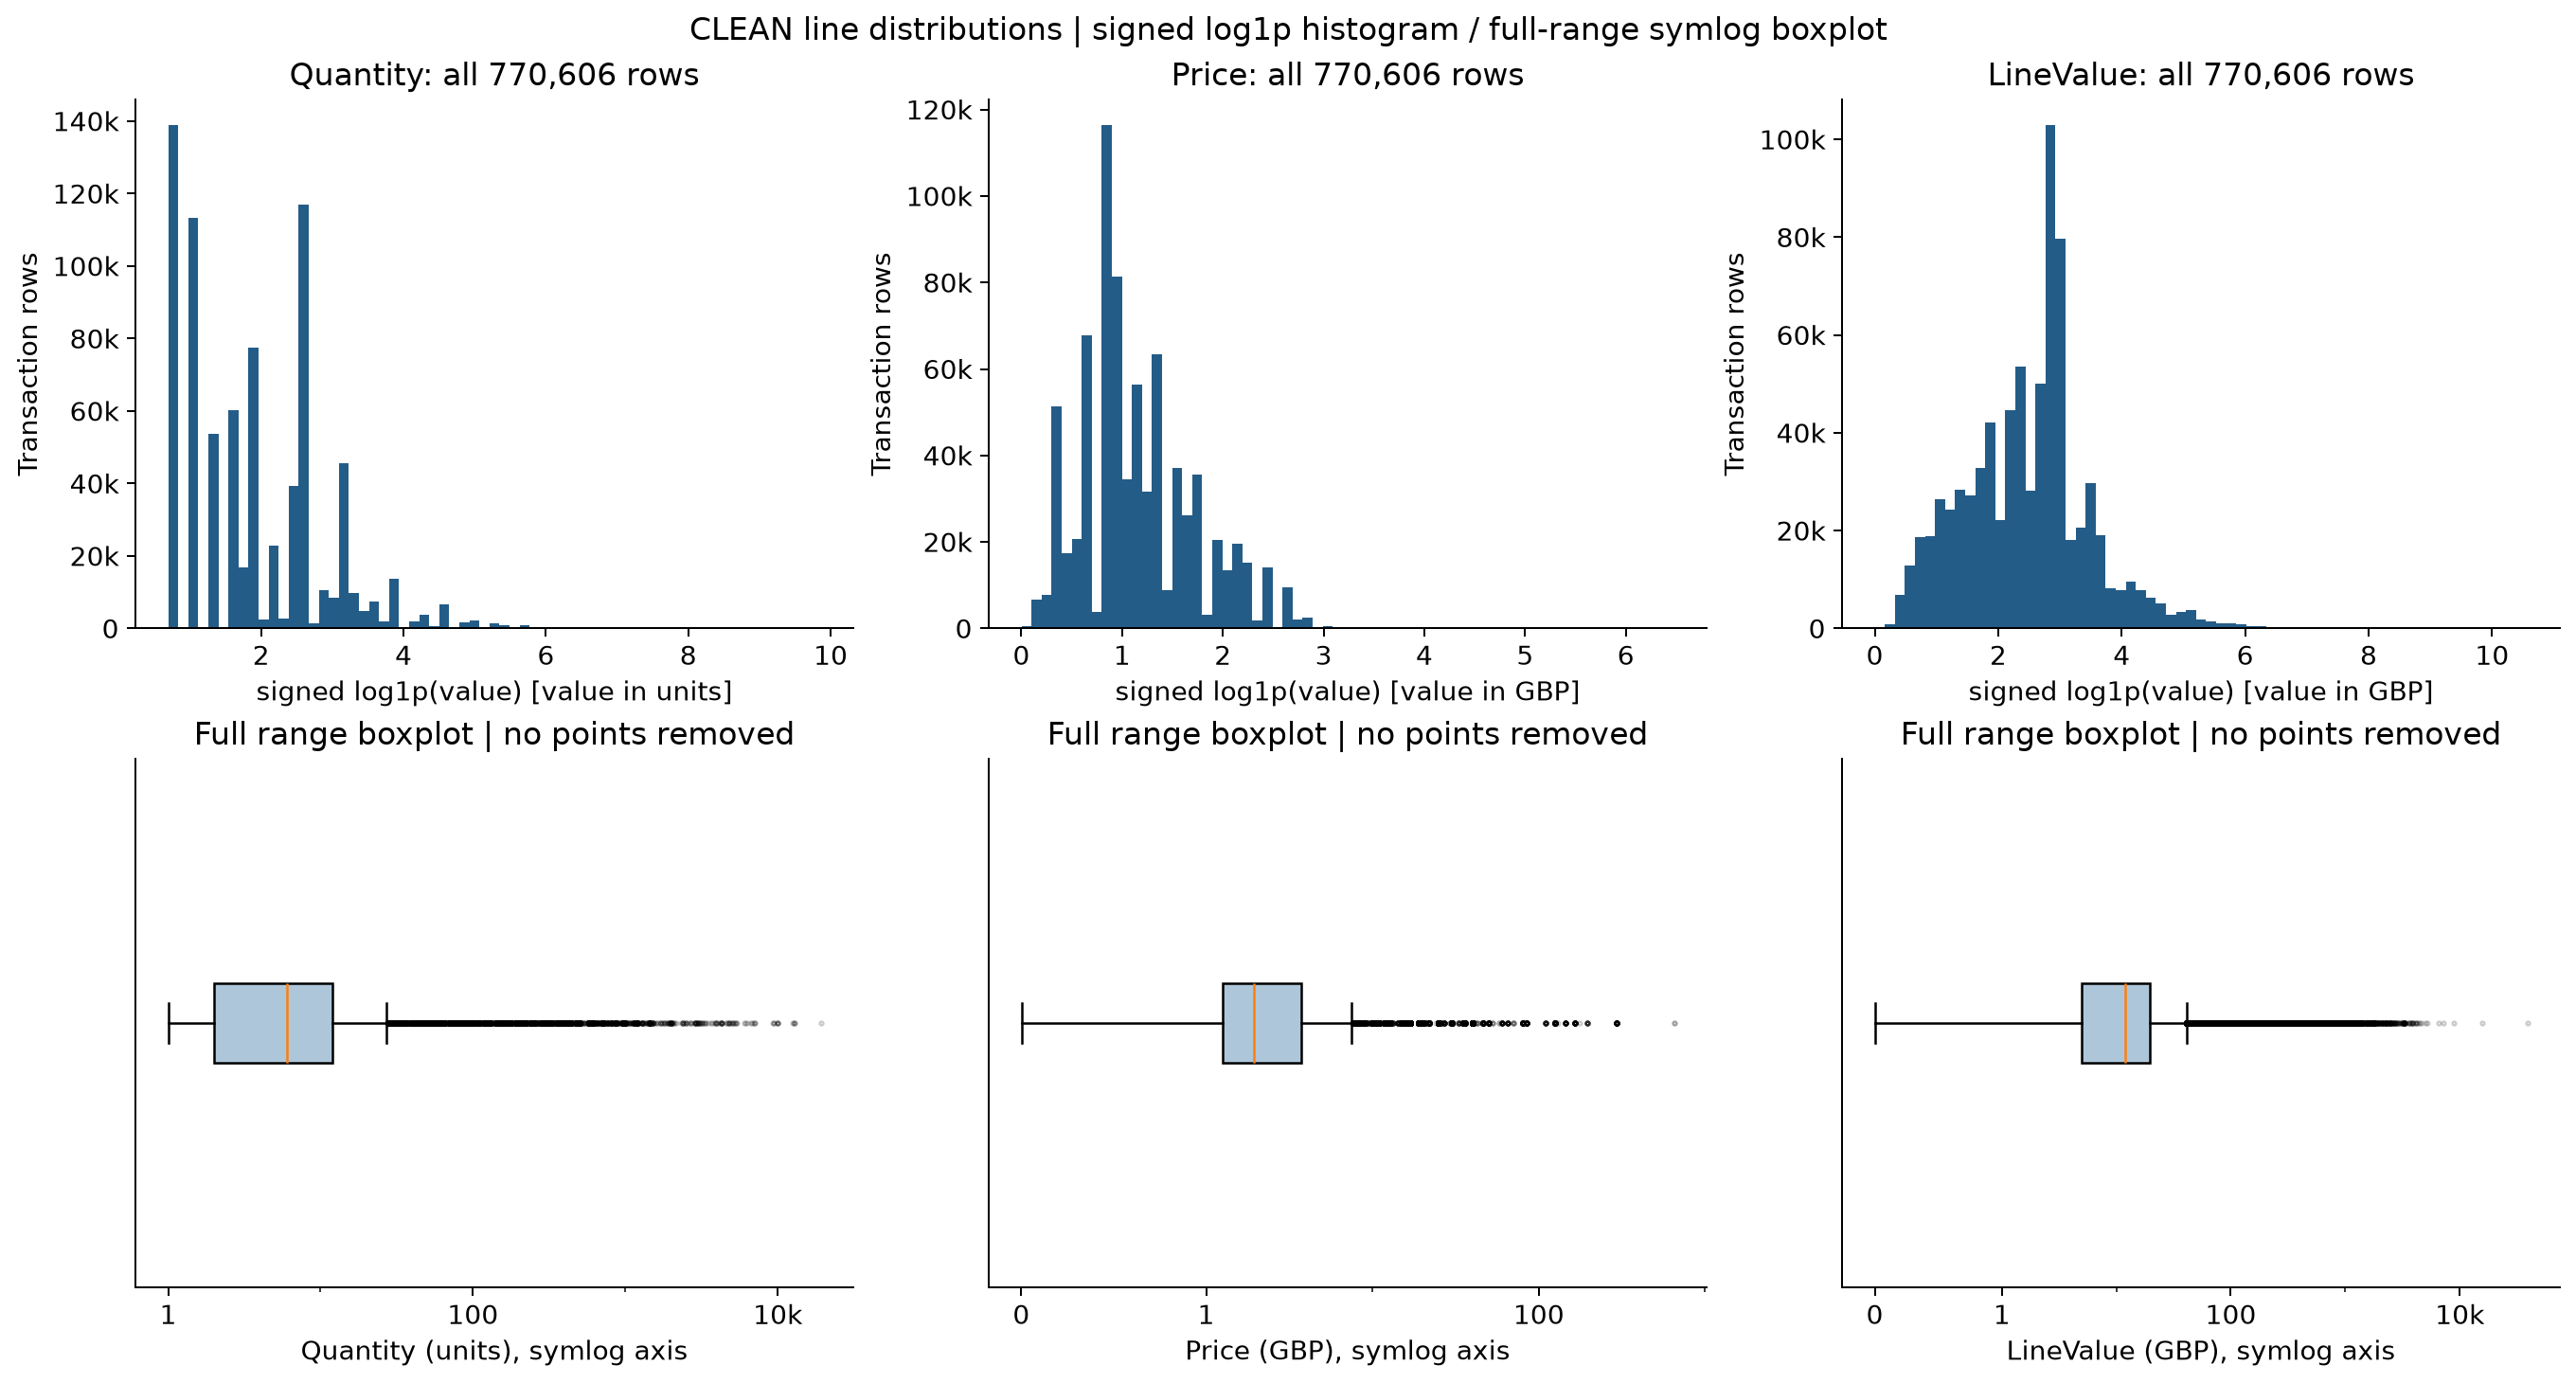

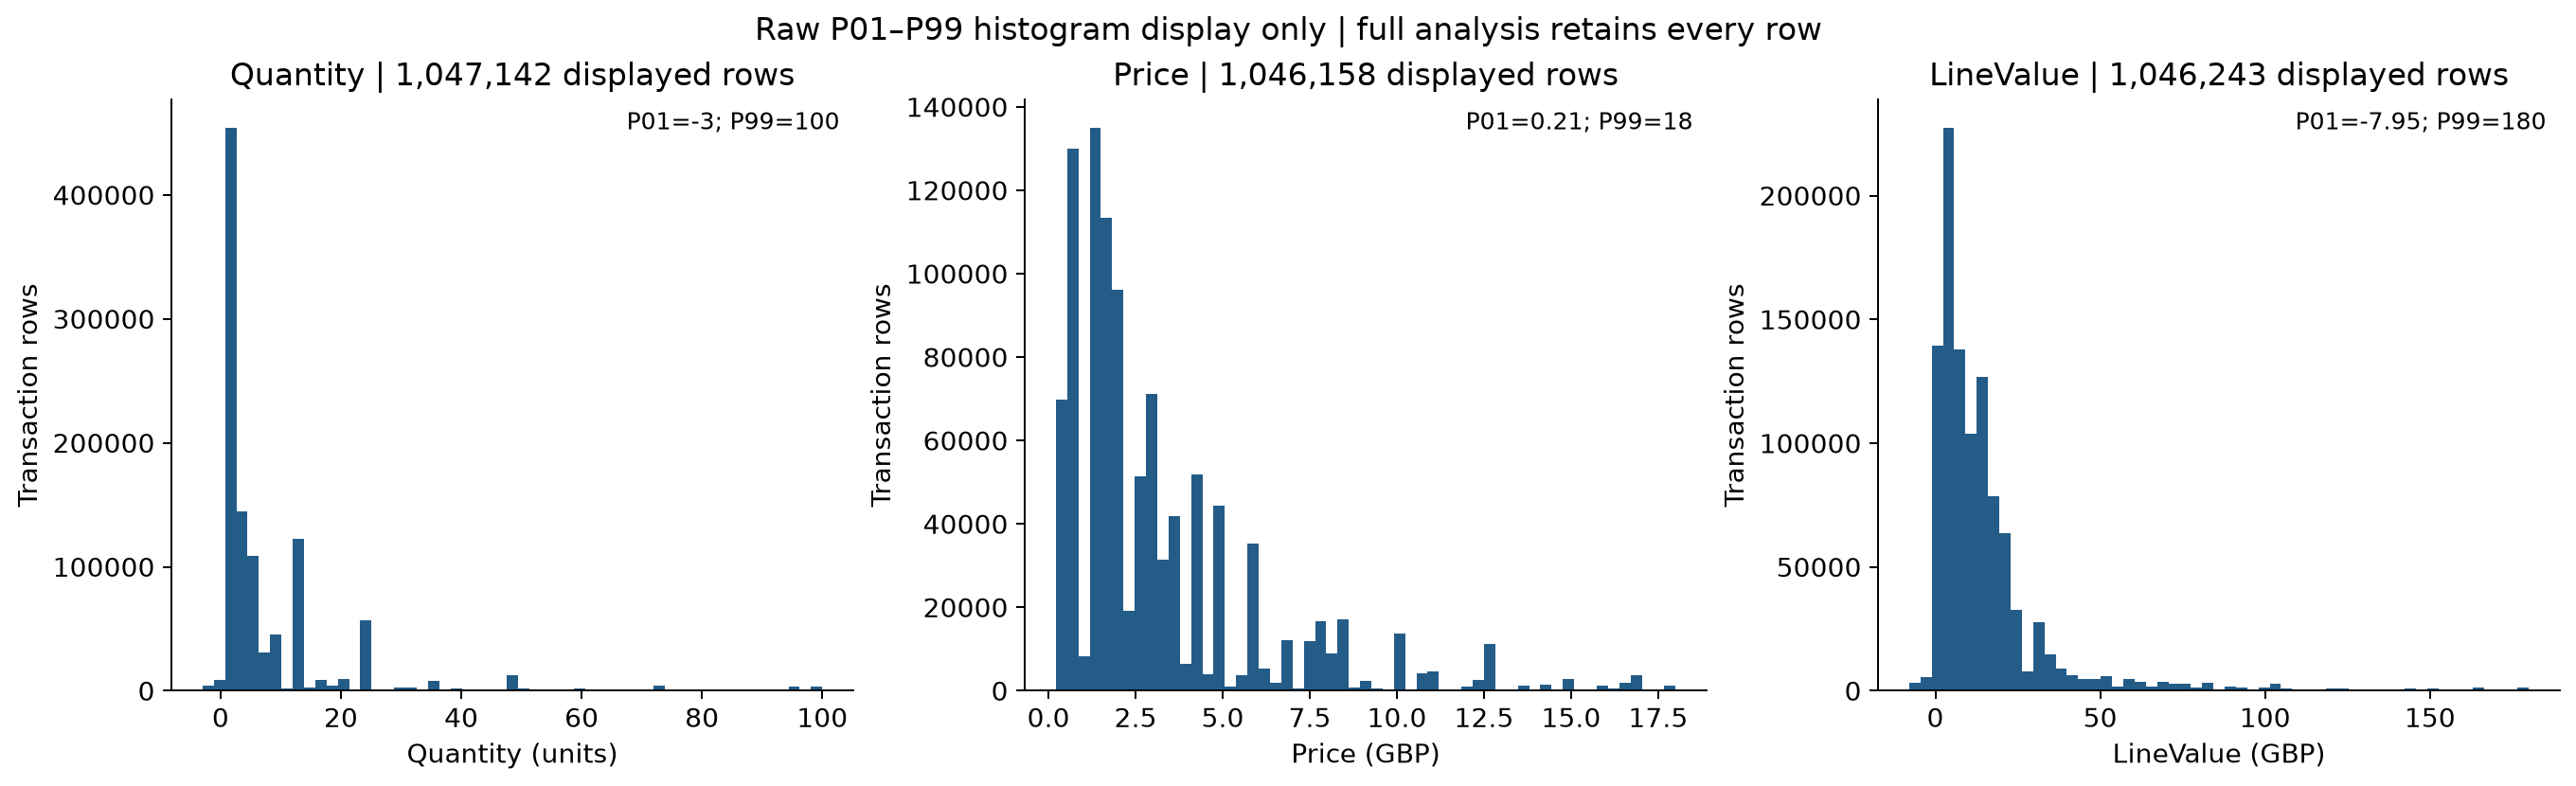

In [17]:
tables["outlier_transactions"] = tables["descriptive_transactions"].copy()
tables["outlier_customers"] = tables["descriptive_customers"].copy()
extremes = []
for variable in ["Quantity", "Price", "LineValue"]:
    for direction, frame in [("smallest", raw.nsmallest(5, variable)), ("largest", raw.nlargest(5, variable))]:
        extremes.append(frame[ORIGINAL_COLUMNS + ["Sheet", "LineValue"]].assign(variable=variable, direction=direction))
tables["extreme_rows"] = pd.concat(extremes, ignore_index=True)

table("outlier_transactions", 20)
table("extreme_rows", 18)

for dataset, frame in [("raw", raw), ("clean", clean)]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for i, variable in enumerate(["Quantity", "Price", "LineValue"]):
        values = frame[variable].to_numpy(float)
        transformed_values = np.sign(values)*np.log1p(np.abs(values))
        axes[0,i].hist(transformed_values, bins=65, color=BLUE)
        axes[0,i].set(title=f"{variable}: all {len(frame):,} rows", xlabel="signed log1p(value)" + (" [value in GBP]" if variable != "Quantity" else " [value in units]"), ylabel="Transaction rows")
        axes[1,i].boxplot(values, orientation="horizontal", patch_artist=True, boxprops={"facecolor":"#AEC6D9"}, flierprops={"markersize":1.5,"alpha":.2})
        axes[1,i].set_xscale("symlog", linthresh=1)
        low_axis, high_axis = axes[1,i].get_xlim()
        axes[1,i].set_xticks([value for value in [-1e6,-1e4,-1e2,-1,0,1,1e2,1e4,1e6] if low_axis <= value <= high_axis])
        count_format(axes[1,i], "x")
        axes[1,i].set(xlabel=f"{variable} ({'units' if variable == 'Quantity' else 'GBP'}), symlog axis", yticks=[], title="Full range boxplot | no points removed")
        count_format(axes[0,i])
    fig.suptitle(f"{dataset.upper()} line distributions | signed log1p histogram / full-range symlog boxplot")
    save(fig, f"{dataset}_transaction_full_distributions.png", f"{dataset} transaction full distributions", f"All {dataset} transaction rows, no outlier deletion", ["outlier_transactions"], "eda_v2_outlier.ipynb")
fig, axes = plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for ax, variable in zip(axes,["Quantity","Price","LineValue"]):
    low,high=raw[variable].quantile([.01,.99])
    displayed_values=raw.loc[raw[variable].between(low,high),variable]
    ax.hist(displayed_values,bins=55,color=BLUE)
    ax.set(title=f"{variable} | {len(displayed_values):,} displayed rows",xlabel=f"{variable} ({'units' if variable=='Quantity' else 'GBP'})",ylabel="Transaction rows")
    ax.text(.98,.98,f"P01={low:g}; P99={high:g}",ha="right",va="top",transform=ax.transAxes,fontsize=10)
fig.suptitle("Raw P01–P99 histogram display only | full analysis retains every row")
save(fig,"raw_transaction_histograms_p01_p99.png","Raw P01–P99 transaction histogram display","Raw rows restricted for display only, no data deletion",["outlier_transactions"],"eda_v2_outlier.ipynb")

**Kết quả:** trên 1,067,371 dòng thô, số điểm ngoài ngưỡng 1,5×IQR là
116,489 với Quantity,
68,105 với Price và
90,922 với LineValue.

**Cách đọc hình:** histogram signed log1p và boxplot symlog giữ toàn miền. Hình P01–P99
chỉ giới hạn hiển thị; không cắt dữ liệu tính toán. Những cờ này chưa chứng minh lỗi dữ liệu.

### Phân phối ở cấp khách hàng

**outlier_customers** — 8 dòng kết quả.

Bảng giữ trong biến `tables["outlier_customers"]`; không xuất CSV trung gian.

,population,variable,count,median,q1,q3,iqr,p95,p99,maximum,outside_iqr,outside_iqr_pct
0,experimental_customers_from_current_pipeline,n_orders,5839,3.0000,1.0000,7.0000,6.0000,20.0000,46.0000,371.0000,423,7.2444
1,experimental_customers_from_current_pipeline,total_purchase_value,5839,851.0100,336.2450,"2,206.9450","1,870.7000","8,990.2870","26,811.0702","579,128.6400",616,10.5498
2,experimental_customers_from_current_pipeline,avg_order_value,5839,274.7600,174.5212,408.3463,233.8251,859.1934,"1,838.7700","19,809.7500",377,6.4566
3,experimental_customers_from_current_pipeline,n_stock_codes_candidate,5839,45.0000,19.0000,103.0000,84.0000,281.0000,502.6200,"2,507.0000",445,7.6212
4,experimental_customers_from_current_pipeline,total_quantity_candidate,5839,480.0000,188.0000,"1,344.0000","1,156.0000","5,259.6000","16,064.4800","365,114.0000",598,10.2415
5,experimental_customers_from_current_pipeline,avg_quantity_per_order_candidate,5839,154.0000,91.5357,258.0000,166.4643,548.5500,"1,296.7001","87,167.0000",358,6.1312
6,experimental_customers_from_current_pipeline,avg_purchase_gap_days,4226,72.9825,39.1898,131.2721,92.0823,323.9684,487.2278,714.1521,308,7.2882
7,experimental_customers_from_current_pipeline,observed_tenure_days,5839,529.4597,311.4979,666.5951,355.0972,735.5169,738.4247,738.6771,0,0.0000


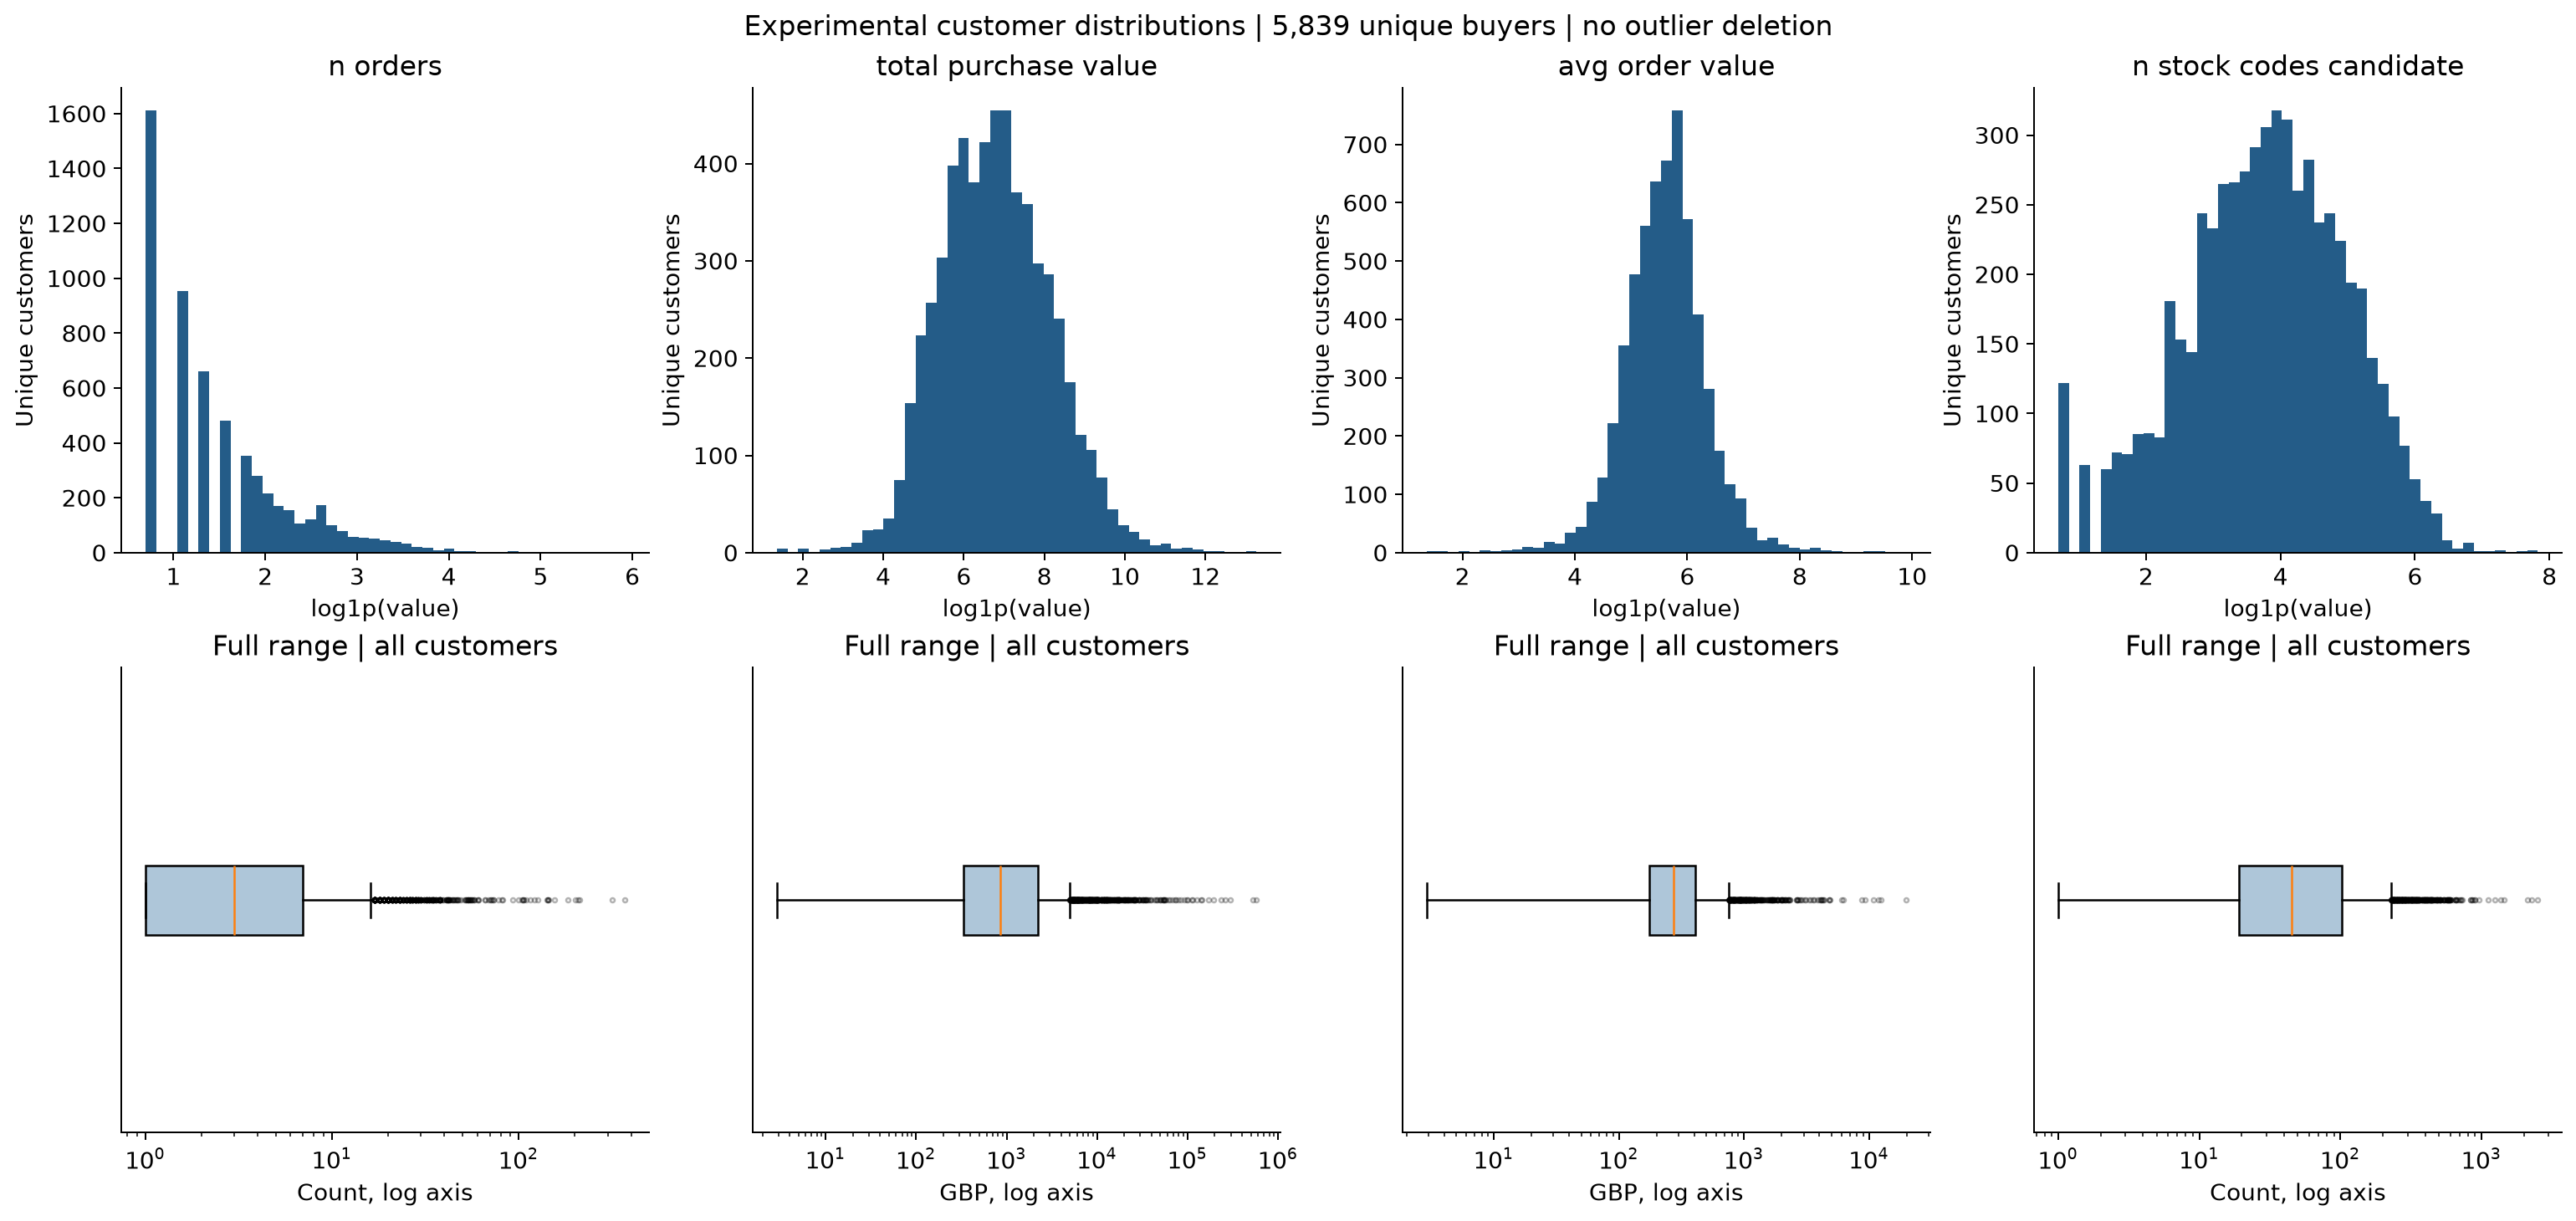

In [18]:
table("outlier_customers", 20)

customer_vars=["n_orders","total_purchase_value","avg_order_value","n_stock_codes_candidate"]
fig, axes=plt.subplots(2,4,figsize=(17,8),layout="constrained")
for i,col in enumerate(customer_vars):
    vals=behavior[col].to_numpy(float)
    axes[0,i].hist(np.log1p(vals),bins=45,color=BLUE)
    axes[0,i].set(title=col.replace("_"," "),xlabel="log1p(value)",ylabel="Unique customers")
    axes[1,i].boxplot(vals,orientation="horizontal",patch_artist=True,boxprops={"facecolor":"#AEC6D9"},flierprops={"markersize":2,"alpha":.3})
    axes[1,i].set_xscale("log")
    axes[1,i].set(xlabel=("GBP, log axis" if col in ["total_purchase_value","avg_order_value"] else "Count, log axis"),yticks=[],title="Full range | all customers")
fig.suptitle(f"Experimental customer distributions | {len(behavior):,} unique buyers | no outlier deletion")
save(fig,"customer_behavior_distributions.png","Customer behavior distributions","One row per current-pipeline buyer; stock counts unverified candidates",["outlier_customers"],"eda_v2_outlier.ipynb")

**Kết quả:** 616/5.839 khách (10,55%) vượt ngưỡng IQR của tổng giá trị mua;
423 khách vượt ngưỡng của số hóa đơn. Giá trị mua lớn nhất được giữ là 579.128,64 GBP.

**Ý nghĩa:** đuôi lớn có thể chi phối khoảng cách Euclid và tâm cụm. Khách ở đuôi có thể
chính là nhóm giá trị cao cần tìm, nên không loại chỉ vì IQR. Thử log1p/scaling và đánh
giá độ ổn định cụm là bước tiếp theo, **Cần nhóm xác nhận** với Thuận trước đổi chính sách.

<a id="eda-rfm"></a>

### Phần bổ sung sau EDA: RFM, log1p và scaling thử nghiệm

**rfm_profile** — 3 dòng kết quả.

Bảng giữ trong biến `tables["rfm_profile"]`; không xuất CSV trung gian.

,population,variable,count,missing,mean,median,minimum,maximum,std,skewness
0,experimental_RFM_full_observation_window,Recency,5839,0,200.2871,95.3632,0.4653,738.5493,208.6361,0.8939
1,experimental_RFM_full_observation_window,Frequency,5839,0,6.2363,3.0000,1.0000,371.0000,12.6765,11.9753
2,experimental_RFM_full_observation_window,Monetary,5839,0,"2,829.6123",851.0100,2.9000,"579,128.6400","13,900.5738",26.6115


**scaling_parameters** — 3 dòng kết quả.

Bảng giữ trong biến `tables["scaling_parameters"]`; không xuất CSV trung gian.

,feature,transform,scaler,mean_log1p,variance_log1p,scale_log1p,fit_customers,window_start,reference_date_exclusive
0,Recency,log1p,StandardScaler(ddof=0),4.4473,2.4378,1.5614,5839,2009-12-01,2011-12-10
1,Frequency,log1p,StandardScaler(ddof=0),1.5457,0.6511,0.8069,5839,2009-12-01,2011-12-10
2,Monetary,log1p,StandardScaler(ddof=0),6.7952,1.9007,1.3786,5839,2009-12-01,2011-12-10


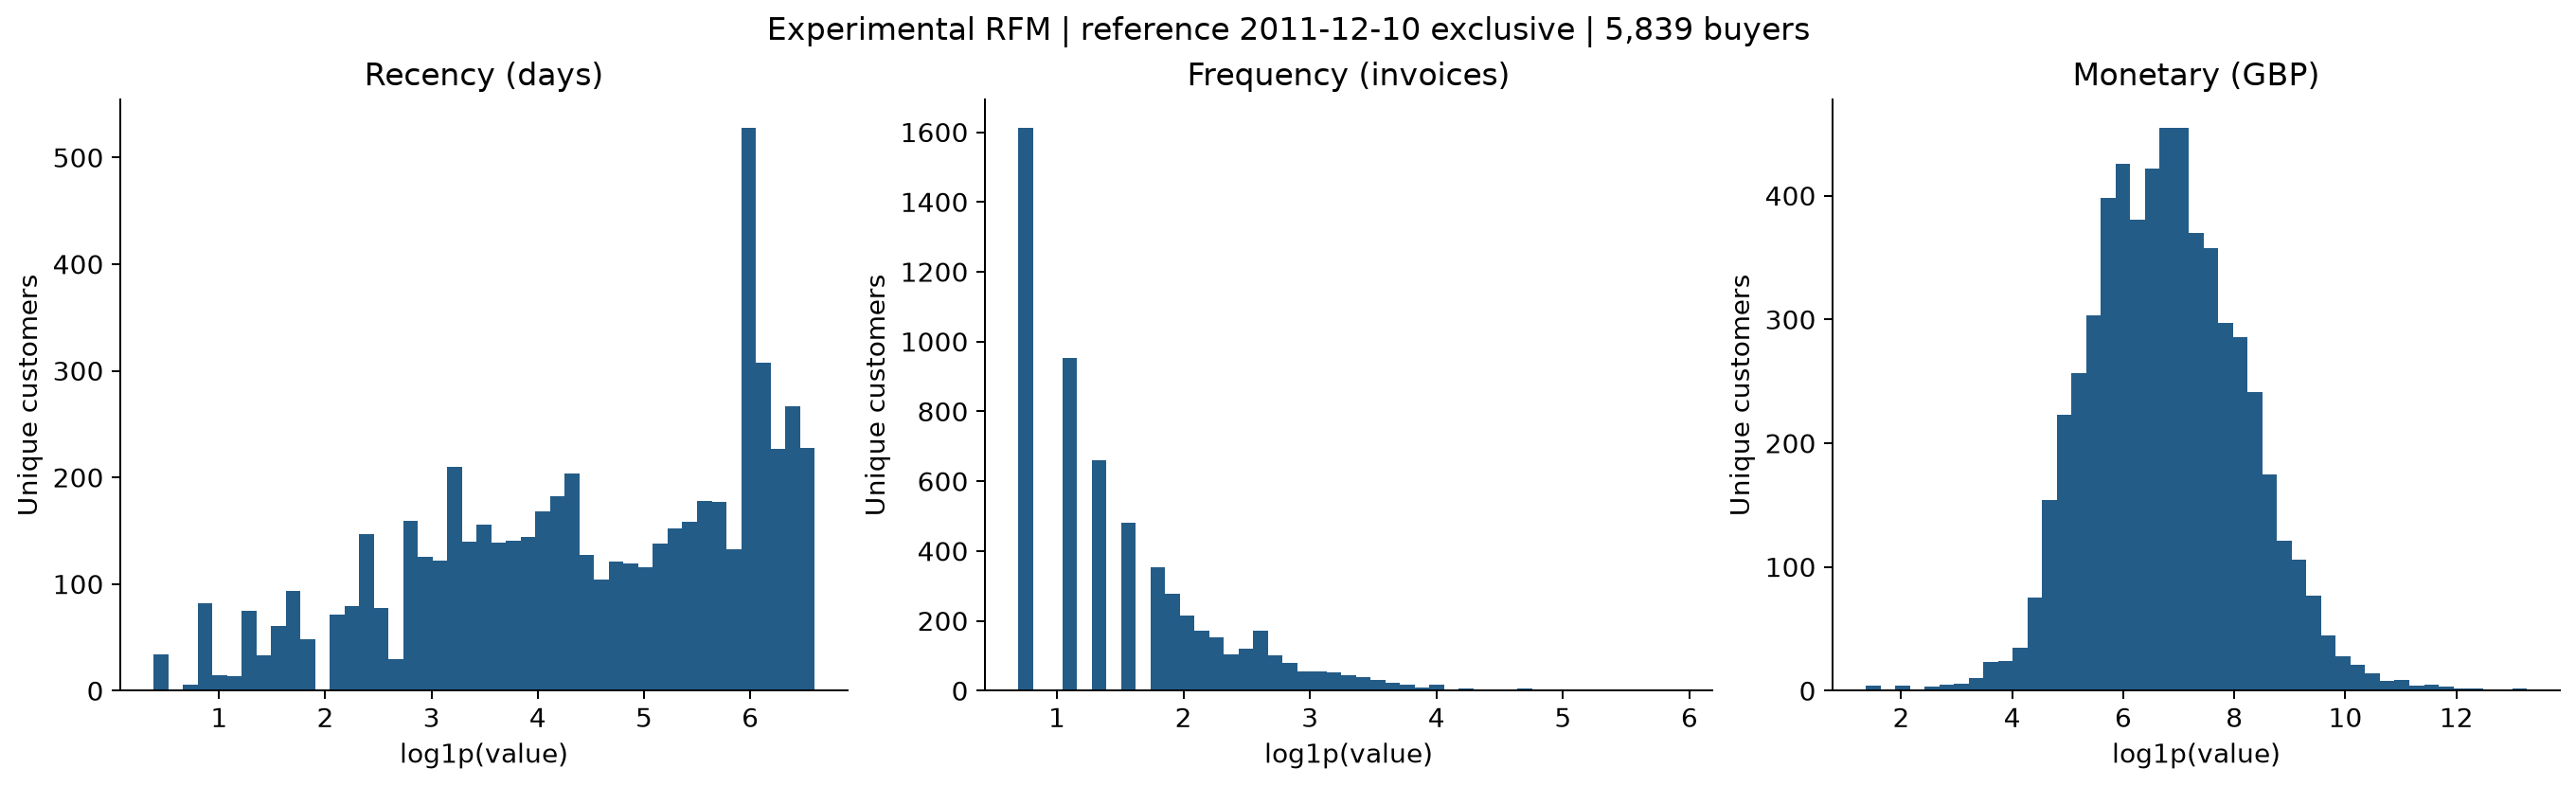

,feature,transform,scaler,mean_log1p,variance_log1p,scale_log1p,fit_customers,window_start,reference_date_exclusive
0,Recency,log1p,StandardScaler(ddof=0),4.4472707841817689,2.4378163993438196,1.5613508251971495,5839,2009-12-01,2011-12-10
1,Frequency,log1p,StandardScaler(ddof=0),1.5457059995631166,0.65111252595813607,0.8069154391620823,5839,2009-12-01,2011-12-10
2,Monetary,log1p,StandardScaler(ddof=0),6.7951831942629211,1.900672948886089,1.3786489578156178,5839,2009-12-01,2011-12-10


In [19]:
rfm = pd.DataFrame({"Customer ID": behavior["Customer ID"],
                    "Recency": (pd.Timestamp(REFERENCE_DATE)-pd.to_datetime(behavior.last_purchase_time)).dt.total_seconds()/86400,
                    "Frequency": behavior.n_orders, "Monetary": behavior.total_purchase_value})
assert rfm["Customer ID"].is_unique and rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()
assert rfm.Recency.gt(0).all()
tables["rfm"] = rfm
tables["rfm_profile"] = descriptive(rfm, ["Recency", "Frequency", "Monetary"], "experimental_RFM_full_observation_window")
logged = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
scaled = scaler.fit_transform(logged)
transformed = rfm[["Customer ID"]].copy()
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    transformed[f"log1p_{col}"] = logged[col]
    transformed[f"z_log1p_{col}"] = scaled[:, i]
tables["rfm_transformed"] = transformed
tables["scaling_parameters"] = pd.DataFrame({"feature": ["Recency", "Frequency", "Monetary"], "transform": "log1p", "scaler": "StandardScaler(ddof=0)",
                                               "mean_log1p": scaler.mean_, "variance_log1p": scaler.var_, "scale_log1p": scaler.scale_,
                                               "fit_customers": len(rfm), "window_start": WINDOW_START, "reference_date_exclusive": REFERENCE_DATE})

table("rfm_profile", 20)
table("scaling_parameters", 20)

fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for ax,col,unit in zip(axes,["Recency","Frequency","Monetary"],["days","invoices","GBP"]):
    ax.hist(np.log1p(rfm[col]),bins=45,color=BLUE)
    ax.set(title=f"{col} ({unit})",xlabel="log1p(value)",ylabel="Unique customers")
fig.suptitle(f"Experimental RFM | reference {REFERENCE_DATE} exclusive | {len(rfm):,} buyers")
save(fig,"rfm_experimental_distributions.png","Experimental RFM distributions","Full observation-window buyers; no official feature designation; no model fitted",["rfm_profile","scaling_parameters"],"eda_v2_outlier.ipynb")

# Preserve exact fitted values in notebook output without a parameter file.
with pd.option_context("display.float_format", lambda value: format(value, ".17g")):
    display(tables["scaling_parameters"])

**Kết quả:** trung vị R ≈ 95,36 ngày, F = 3 hóa đơn và M = 851,01 GBP trên 5.839 khách.
Mốc tham chiếu là 10/12/2011, loại trừ; R dùng thời điểm mua theo chính sách hóa đơn,
F đếm Invoice duy nhất và M cộng Q×P chính xác của các dòng được giữ.

**Giới hạn:** log1p rồi StandardScaler được fit trên snapshot khảo sát, có lưu tham số.
Đây là chuẩn bị dữ liệu, chưa có kết quả mô hình hoặc bằng chứng phương án scale tốt nhất.
Với đánh giá theo thời gian, fit biến đổi trên tập phù hợp và không dùng hủy tương lai.

## 10. Lưu kết quả và kiểm tra

Các cell dưới tính 35 bảng trong notebook, chỉ xuất 3 CSV bàn giao và 16 PNG. Báo cáo Markdown đã có được giữ như
bản chi tiết; Run All cập nhật kết quả tính toán, không ghi lại văn bản báo cáo.
Checksum nguồn/module và phiên bản thư viện được hiển thị trực tiếp trong notebook.

In [20]:
summary.update(raw_rows=len(raw), raw_columns=8, raw_invoices=int(raw.Invoice.nunique()), raw_customers=int(raw["Customer ID"].nunique()),
               raw_countries=int(raw.Country.nunique()), raw_date_min=str(raw.InvoiceDate.min()), raw_date_max=str(raw.InvoiceDate.max()),
               raw_signed_value_gbp=float(raw.LineValue.sum()), missing_customer_rows=int(raw["Customer ID"].isna().sum()),
               missing_customer_pct=float(raw["Customer ID"].isna().mean()*100), missing_description_rows=int(raw.Description.isna().sum()),
               duplicate_excess=duplicate_excess, duplicate_within_sheets=within, shared_patterns=len(shared), shared_second_sheet_rows=shared_second_rows,
               overlap_start=str(start), overlap_end=str(end), clean_rows=len(clean), clean_invoices=int(clean.Invoice.nunique()), clean_customers=int(clean.CustomerID.nunique()),
               cancellation_rows=len(cancel), cancellation_invoices=int(cancel.Invoice.nunique()), cancellation_customers=int(cancel.CustomerID.nunique()),
               reversal_removed_rows=int(reverse.sum()), clean_rounded_value_gbp=rounded_total, clean_exact_value_gbp=clean_exact_total,
               rounding_delta_gbp=rounded_total-clean_exact_total, clean_rounded_zero_rows=int(clean.LineValue.eq(0).sum()),
               single_invoice_customers=singles, single_invoice_pct=100*singles/len(behavior), customer_gap_missing=singles,
               country_dominant=str(country.iloc[0].Country), country_dominant_rows=int(country.iloc[0].rows),
               country_dominant_rows_pct=float(country.iloc[0].rows_pct),
               stored_outputs_equal=all(bool(item["equal"]) for item in reconciliation),
               customer_orders_value_spearman=float(tables["customer_summary"].spearman_orders_value.iloc[0]),
               window_start=WINDOW_START, reference_date_exclusive=REFERENCE_DATE,
               figures_count=len(figures), all_product_features_missing=True, return_rate_all_missing=True,
               rfm_status="Experimental only; Cần nhóm xác nhận window, invoice, service, duplicate and cancellation policies",
               models_run=False)

display(pd.Series(summary, name="Kết quả").to_frame())

source_after=checksum(source)
assert source_before==source_after, "Source workbook changed during analysis"
assert all(checksum(project / name) == before_hash for name, before_hash in code_before.items()), "Analysis source changed during execution; rerun before accepting outputs"
for relative,before_hash in stored_hashes.items():
    assert checksum(project/relative)==before_hash, f"Stored processed input changed: {relative}"
for name in EXPORT_TABLES:
    tables[name].to_csv(table_dir/f"{name}.csv", index=False, encoding="utf-8-sig")
# Keep reproducibility information in saved notebook outputs, not JSON sidecars.
display(pd.DataFrame([
    {"input": "data/raw/online_retail_II.xlsx", "SHA256": source_before},
    *[{"input": name, "SHA256": digest} for name, digest in code_before.items()]
]))
versions = {"python": platform.python_version(), **{name: importlib.metadata.version(name)
            for name in ["pandas", "numpy", "matplotlib", "scikit-learn", "openpyxl"]}}
display(pd.Series(versions, name="version").to_frame())
print(f"Computed {len(tables)} tables; exported {len(EXPORT_TABLES)} handoff CSVs and {len(figures)} PNGs. No JSON output.")

,Kết quả
raw_rows,1067371
raw_columns,8
raw_invoices,53628
raw_customers,5942
raw_countries,43
raw_date_min,2009-12-01 07:45:00
raw_date_max,2011-12-09 12:50:00
raw_signed_value_gbp,"19,287,250.5680"
missing_customer_rows,243007
missing_customer_pct,22.7669


,input,SHA256
0,data/raw/online_retail_II.xlsx,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980
1,src/preprocessing.py,301fc8fbca2beffa15c205cb278c740008992d6f09dd53730de7006b1d2c256e
2,src/features.py,9b65f8258129d6ca935566208fcd9812c7fdabebc203e4b5b53cb8b65bae71a3


,version
python,3.12.15
pandas,3.1.0
numpy,2.5.4
matplotlib,3.11.2
scikit-learn,1.9.1
openpyxl,3.1.5


Computed 35 tables; exported 3 handoff CSVs and 16 PNGs. No JSON output.


<a id="eda-checks"></a>

## 11. Kết luận và liên kết báo cáo

EDA xác định vấn đề dữ liệu, tái lập pipeline và khảo sát hành vi/ngoại lệ/RFM. Bản báo cáo
18 mục đã hoàn thành được giữ riêng để đọc chi tiết. Nếu đổi dữ liệu hoặc chính sách,
cập nhật phần diễn giải và báo cáo dựa trên kết quả tính lại, không dùng số liệu cũ.

**Cần nhóm xác nhận:** danh mục sản phẩm, ghép hủy, trùng, thời điểm hóa đơn, cách làm tròn,
cửa sổ và biến đổi trước khi chọn mô hình. Không loại khách IQR hoặc điền return_rate=0.


In [21]:
assert len(tables) == 35 and len(figures) == 16
assert summary["stored_outputs_equal"]
assert checksum(source) == source_before
for figure in figures:
    with PILImage.open(figure_dir / figure["name"]) as png:
        png.verify()
report_path = PROJECT / "reports/bao_cao_qua_trinh_eda.md"
if report_path.exists():
    for reference in re.findall(r"!?\[[^\]]*\]\(([^)]+)\)", report_path.read_text(encoding="utf-8")):
        if "://" not in reference and not reference.startswith("#"):
            assert (report_path.parent / reference.split("#")[0]).exists(), reference
    display(Markdown("[Đọc báo cáo EDA đã hoàn thành](../../reports/bao_cao_qua_trinh_eda.md)"))
display(Markdown(f"**Hoàn thành:** {len(tables)} bảng trong notebook, {len(EXPORT_TABLES)} CSV bàn giao, {len(figures)} PNG; dữ liệu nguồn và processed giữ nguyên."))

[Đọc báo cáo EDA đã hoàn thành](../../reports/bao_cao_qua_trinh_eda.md)

**Hoàn thành:** 35 bảng trong notebook, 3 CSV bàn giao, 16 PNG; dữ liệu nguồn và processed giữ nguyên.